# E121 · Did they cheat? Five models between a chess game and an accusation

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: rated blitz games played on Lichess from July to December 2014, from the **Lichess open database** (released under CC0), with the engine evaluations the site attached to about one game in six: 2,541 accounts, the results of their 1.5 million games, and 56,540 analysed games. Real labels, with limits: whether the public Lichess API reports the account today as **marked for a violation of the terms of service**. Account names are replaced by codes, and nothing is simulated |
| **You will learn** | Chaining models so that each one feeds the next: a **random-walk rating**, fitted on a subset and extended by a fast smoother · a **move-quality model** that knows how hard the position is · a **surprise score** whose spread is measured, not assumed · a **mixture with a base rate**, on a case-control sample · an **accusation threshold** set by the cost of a false accusation, with posterior bands · a test on 1,000 accounts no model has seen · and the habit of E120: what we chose, what we rejected and what would change our mind, at every step |

## The question

A chess engine on a telephone plays better than the strongest humans. On a chess site that makes
cheating easy to do and hard to prove: there is no arbiter and no camera, only the moves. Every large
site therefore has a fair-play team, and the question that reaches it all day has one form: *this
account plays too well; did they cheat?*

The statistical idea behind an answer is reasonable. An engine can grade every move of a game, so a
player can be rated, in the words of Regan and Haworth (2011), "intrinsically by the quality of their
decisions", and not only by results. If the moves are far better than the rating predicts, something
is off. The usual summary is a z-score: by how many standard deviations did this player beat
expectation?

Two warnings about that z-score were put to us before we started, and we treat both as hypotheses to
test. The first: expectation needs a rating, and a rating describes yesterday's player, so a simple
z-score flags every fast-improving junior. The second: even a good detector mostly accuses innocent
players when cheating is rare, because a small false-alarm rate in a large honest population
outnumbers the true alarms.

Answering takes a chain of models. How strong is the account at the time of each game? How good should
the moves of a player of that strength be *in those positions*, given that an engine, as Lichess says
of its own accuracy score, "can assess the soundness of our moves, it can't tell us how difficult it
is to find them"? How surprising is one game? How probable is a violation, given the surprise and
given how rare violations are? And where should the line be drawn, when a false accusation costs more
than a miss? At every link the first model we try is usually wrong, and one that we fully intended to
keep does not survive its own check. The path looks like this.

In [1]:
import os

for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(name, "1")  # before NumPy: one BLAS thread per chain

import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from scipy import optimize, special, stats

from pymc_challenges import data

sys.modules.pop("jax", None)   # ArviZ's lazy JAX stub; nothing here uses JAX (see E89, E118)

RANDOM_SEED = 121
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
plt.rcParams.update({"axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9})
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
T_START = time.time()

INK, MUTED, LIGHT, GRID = "#222222", "#8a8a8a", "#d9d9d9", "#e1e0d9"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
SEQ = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#cde2fb", "#6da7ec", "#256abf", "#0d366b"])


def tidy(ax, grid="y"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(False)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.6)
    ax.set_axisbelow(True)


def diagnostics(idata):
    """Divergences, worst r_hat and lowest effective sample size of a fit, as one line."""
    rhat, ess = az.rhat(idata), az.ess(idata)
    return (f"divergences {int(idata.sample_stats['diverging'].sum())}, "
            f"max r_hat {max(float(rhat[v].max()) for v in rhat.data_vars):.3f}, "
            f"min ESS {min(float(ess[v].min()) for v in ess.data_vars):.0f}")

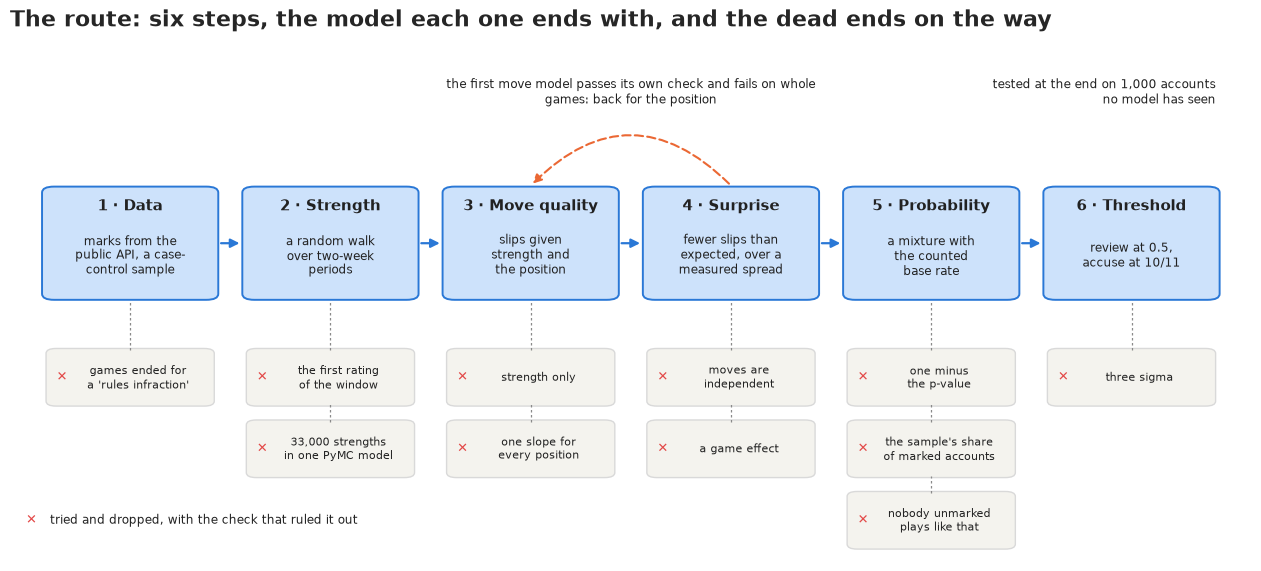

In [2]:
ROUTE = [  # step, what we end up using, what we try and drop on the way
    ("1 · Data", "marks from the\npublic API, a case-\ncontrol sample", ["games ended for\na 'rules infraction'"]),
    ("2 · Strength", "a random walk\nover two-week\nperiods", ["the first rating\nof the window", "33,000 strengths\nin one PyMC model"]),
    ("3 · Move quality", "slips given\nstrength and\nthe position", ["strength only", "one slope for\nevery position"]),
    ("4 · Surprise", "fewer slips than\nexpected, over a\nmeasured spread", ["moves are\nindependent", "a game effect"]),
    ("5 · Probability", "a mixture with\nthe counted\nbase rate",
     ["one minus\nthe p-value", "the sample's share\nof marked accounts", "nobody unmarked\nplays like that"]),
    ("6 · Threshold", "review at 0.5,\naccuse at 10/11", ["three sigma"]),
]

fig, ax = plt.subplots(figsize=(12.5, 5.6))
for i, (step, kept, dropped) in enumerate(ROUTE):
    ax.add_patch(FancyBboxPatch((i - 0.42, 2.55), 0.84, 1.1, boxstyle="round,pad=0.02,rounding_size=0.06",
                                fc="#cde2fb", ec=BLUE, lw=1.4))
    ax.text(i, 3.47, step, ha="center", va="center", fontsize=10.5, fontweight="bold", color=INK)
    ax.text(i, 2.98, kept, ha="center", va="center", fontsize=8.6, color=INK, linespacing=1.25)
    if i < len(ROUTE) - 1:
        ax.add_patch(FancyArrowPatch((i + 0.44, 3.1), (i + 0.56, 3.1), arrowstyle="-|>", mutation_scale=13,
                                     color=BLUE, lw=1.6))
    for k, text in enumerate(dropped):
        y = 1.75 - 0.72 * k
        ax.plot([i, i], [y + 0.27, y + 0.45 if k else 2.53], color=MUTED, lw=0.9, ls=(0, (2, 2)))
        ax.add_patch(FancyBboxPatch((i - 0.4, y - 0.27), 0.8, 0.54, boxstyle="round,pad=0.02,rounding_size=0.05",
                                    fc="#f4f3ee", ec=LIGHT, lw=1.0))
        ax.text(i - 0.34, y, "✕", ha="center", va="center", fontsize=9, color=RED, fontweight="bold")
        ax.text(i + 0.04, y, text, ha="center", va="center", fontsize=8.1, color=INK, linespacing=1.2)
ax.add_patch(FancyArrowPatch((3.0, 3.68), (2.0, 3.68), connectionstyle="arc3,rad=0.5", arrowstyle="-|>",
                             mutation_scale=13, color=ORANGE, lw=1.5, ls=(0, (4, 2))))
ax.text(2.5, 4.62, "the first move model passes its own check and fails on whole\ngames: back for the position",
        ha="center", va="center", fontsize=8.6, color=INK)
ax.text(5.42, 4.62, "tested at the end on 1,000 accounts\nno model has seen", ha="right", va="center", fontsize=8.6, color=INK)
ax.text(-0.52, 0.31, "✕", fontsize=9, color=RED, fontweight="bold", va="center")
ax.text(-0.4, 0.31, "tried and dropped, with the check that ruled it out", fontsize=8.6, color=INK, va="center")
ax.set_xlim(-0.6, 5.6)
ax.set_ylim(-0.1, 5.2)
ax.axis("off")
ax.set_title("The route: six steps, the model each one ends with, and the dead ends on the way", loc="left");

Blue boxes are the steps and the model each one ends up with. Grey boxes are what we try first and
drop, each ruled out by a check we will show. The orange arrow is where the analysis runs backwards.
Each step closes with a short box, **The choice**: what we kept, what we rejected and why, and what
evidence would make us choose differently. The last part redoes the decision under the rejected
choices.

| part | question | tool |
|---|---|---|
| 1 | What is measured, and what does a mark mean? | a case-control sample, winning chances, slips |
| 2 | How strong is an account at the time of each game? | a random walk in PyMC, a smoother, held-out results |
| 3 | How often should a player of that strength slip in this position? | binomial regressions on counted cells, a check on whole games |
| 4 | How surprising is one game? | z-scores, a game effect that fails, a fitted spread, accuracy fingerprints |
| 5 | How probable is a mark, given the score? | a two-group mixture with a counted base rate |
| 6 | Whom to review, whom to accuse? | cost curves with posterior bands |
| 7 | Does the chain hold on accounts it has not seen? | 1,000 held-out accounts |
| 8 | Which of our choices mattered? | the decision redone under every rejected choice |

## 1 · The data: what is measured, and what a mark means

In [3]:
data.describe("e121_chess_accounts")
data.describe("e121_chess_results")
data.describe("e121_chess_games")
acc = data.load("e121_chess_accounts")
res = data.load("e121_chess_results")
games = data.load("e121_chess_games")
A, P = len(acc), 13
acc["gain"] = acc["elo_last"] - acc["elo_first"]
N_MARKED, N_UNMARKED = acc.loc[acc["marked"] == 1, "weight"].sum(), acc.loc[acc["marked"] == 0, "weight"].sum()
BASE_RATE = N_MARKED / (N_MARKED + N_UNMARKED)
print(f"\n{A:,} sampled accounts, {int(acc['marked'].sum())} of them marked; {res['n'].sum():,} results; {len(games):,} analysed games")
print(f"in the sample {acc['marked'].mean():.1%} of accounts are marked; among all {N_MARKED + N_UNMARKED:,.0f} eligible "
      f"accounts {BASE_RATE:.1%} are")
print(f"accounts whose first rating of the window is exactly 1500, the default: {(acc['elo_first'] == 1500).mean():.0%}")
acc["train"] = rng.random(A) < 0.6
print("accounts for fitting:", int(acc["train"].sum()), f"({int((acc['train'] & (acc['marked'] == 1)).sum())} marked);",
      "set aside for the final test:", int((~acc["train"]).sum()), f"({int((~acc['train'] & (acc['marked'] == 1)).sum())} marked)")
games.head(3)

e121_chess_accounts: One row per sampled account, names replaced by codes (2,541 rows). Eligible: at least 60 rated blitz games in the six months, at least 16 of them analysed games with engine evaluations, and not closed today (8,886 eligible, 1,246 closed and left out). ALL 541 eligible accounts that the API reports as marked are kept, with a random 2,000 of the 7,099 others: a case-control sample. Columns: account (A0001...), marked (1 if the API reports the account as marked for a terms-of-service violation, which the Lichess source sets for engine assistance or boosting; as of 2026, not 2014), weight (eligible accounts of that kind per sampled account: 1 for marked, 3.5495 for the others), n_blitz (rated blitz games in the window), n_analysed (usable analysed games among them), elo_first (published blitz rating before the first game of the window), elo_last (after the last).
  source: Lichess open database, rated standard games of July to December 2014 (six monthly .pgn.zst files,


2,541 sampled accounts, 541 of them marked; 1,479,778 results; 56,540 analysed games
in the sample 21.3% of accounts are marked; among all 7,640 eligible accounts 7.1% are
accounts whose first rating of the window is exactly 1500, the default: 46%
accounts for fitting: 1541 (334 marked); set aside for the final test: 1000 (207 marked)


,game,period,white,black,white_elo,black_elo,result,plies,evals,flags
0,G00001,1,,A2293,1710,1748,0-1,92,26 24 23 13 20 26 -7 34 37 36 34 68 56 67 57 1...,0000000110110000000000000110011110000003100000...
1,G00002,10,,A1143,1406,1615,0-1,118,-6 1 -3 26 28 29 29 24 37 32 26 41 49 39 1 -4 ...,0000000000011000000000000000011000100101101111...
2,G00003,3,A0108,A0680,962,1561,0-1,74,26 44 32 38 13 29 32 23 -8 -10 -17 -21 -34 -41...,0000000000000000000113111113100000000000011112...


The three tables come from six monthly files of the Lichess database, 6.7 million games, streamed once
by `tools/build_e121_chess.py`. We keep rated blitz games, because Lichess has a separate rating for
each speed. **Accounts** are the unit we end up judging. **Results** hold every rated blitz game of
each sampled account, counted by fortnight and by the opponent's rating. **Games** hold up to 24
analysed games per account, with the engine's evaluation after every half-move. The builder drops
whatever identifies a game (its address, the clock time, the opening, the moves themselves) and
replaces account names by codes. This notebook is about patterns across 2,541 accounts and has nothing
to say about any one of them.

**What a mark is.** The column `marked` is real, and it is not ground truth. It says that the public
Lichess API reports the account, today, as having violated the terms of service. The Lichess source
sets that flag for two different offences, engine assistance and boosting (arranging results to move
a rating), and does not say which. It is dated 2026, twelve years after the games, and it is a verdict
on an account, not on any game. An account that is closed today shows no flag at all, so the builder
leaves closed accounts out: 1,246 of the 8,886 eligible ones. A false accusation, in this notebook,
means accusing an account that the platform has not marked. Some of those may be cheats that nobody
caught.

**A dead end before the first model.** The database has a field that looks like a label: a game can end
with the termination "Rules infraction", which the Lichess source writes when the status of the game is
"cheat". We checked it on the raw file of July 2014 (the derived tables do not carry that field, so
the check is not repeated here). The file has 122 such games, and more than four in five of the
accounts that lost them went on playing later in the month, which a banned account does not do. It
was not a verdict we could use.

**The sample is lopsided on purpose.** Of the 7,640 eligible accounts that are still open, 541 are
marked: 7.1%. The file keeps all 541 and a random 2,000 of the other 7,099, so 21% of the accounts in
the file are marked. This is a case-control sample: the share of marked accounts *in the file* is
three times their share in the population. Each account carries a `weight`, the number of eligible
accounts it stands for. Part 5 shows what happens to an analyst who forgets it.

Before any model sees them, 1,000 accounts are set aside for the test of part 7. Everything in parts 3
to 6 is fitted on the other 1,541.

**The measure.** An engine evaluation is in centipawns, hundredths of a pawn, from White's side.
Lichess turns it into a winning chance with a logistic curve, $W = 100 / (1 + e^{-0.00368\,c})$, and
we use the same curve. The cost of a move is the winning chance its player had before it minus the
winning chance after it. We judge moves from each side's sixth on, since the first five are mostly
memory, and we call a move a **slip** when it costs two points or more.

In [4]:
K_WIN = 0.00368208          # Lichess's map from centipawns to winning chances
FIRST_PLY = 10              # judge moves from each side's sixth; the first five are mostly memory
SLIP = 2.0                  # a slip: a move that gives up at least two points of winning chance
BEF_EDGES = np.array([0, 1, 5, 20, 35, 45, 55, 65, 80, 95, 99, 100.0])
BEF_LABELS = ["under 1", "1-5", "5-20", "20-35", "35-45", "45-55", "55-65", "65-80", "80-95", "95-99", "over 99"]
OPP_EDGES = np.array([0, 1, 5, 10, 20, 100.0])
OPP_LABELS = ["under 1", "1-5", "5-10", "10-20", "over 20"]
PHASE_EDGES = np.array([0, 3, 6, 10, 15, 99])
PHASE_LABELS = ["0-2", "3-5", "6-9", "10-14", "15 or more"]


def win_chance(evals):
    """White's winning chance (0-100) after each half-move, from the evaluation string of one game."""
    ev = evals.split(" ")
    if ev[-1] == "":                                   # a final mating move has no evaluation
        ev = ev[:-1]
    cp = np.array([3000.0 if e == "M" else -3000.0 if e == "-M" else float(e) for e in ev])
    w = 100 / (1 + np.exp(-K_WIN * np.clip(cp, -2000, 2000)))
    w[cp >= 3000], w[cp <= -3000] = 100.0, 0.0
    return w


def move_table(games):
    """One row per judged move: who moved, the position before it, and the winning chance it gave up."""
    out = {k: [] for k in ("g", "ply", "white", "before", "loss", "opp_gave", "captures", "in_check", "recapture")}
    for gi, (evals, flags) in enumerate(zip(games["evals"], games["flags"])):
        w = win_chance(evals)
        fl = np.frombuffer(flags[:len(w)].encode(), dtype=np.uint8) - 48
        ply = np.arange(1, len(w))                     # move at half-move ply needs the evaluation before it
        white = ply % 2 == 0
        before = np.where(white, w[:-1], 100 - w[:-1])
        loss = np.maximum(before - np.where(white, w[1:], 100 - w[1:]), 0)
        keep = ply >= FIRST_PLY
        cap = fl & 1
        for k, v in zip(out, (np.full(keep.sum(), gi), ply[keep], white[keep], before[keep], loss[keep],
                              np.concatenate([[0.0], loss[:-1]])[keep], np.cumsum(cap)[:-1][keep],
                              ((fl[:-1] >> 1) & 1)[keep], cap[:-1][keep])):
            out[k].append(v)
    return pd.DataFrame({k: np.concatenate(v) for k, v in out.items()})


t0 = time.time()
mv = move_table(games)
code = pd.Index(acc["account"])
mv["a"] = code.get_indexer(np.where(mv["white"], games["white"].to_numpy()[mv["g"]], games["black"].to_numpy()[mv["g"]]))
mv["published"] = np.where(mv["white"], games["white_elo"].to_numpy()[mv["g"]], games["black_elo"].to_numpy()[mv["g"]])
mv["period"] = games["period"].to_numpy()[mv["g"]]
mv["slip"] = mv["loss"] >= SLIP
mv["bef"] = np.clip(np.searchsorted(BEF_EDGES, mv["before"], side="right") - 1, 0, 10)
mv["opp"] = np.clip(np.searchsorted(OPP_EDGES, mv["opp_gave"], side="right") - 1, 0, 4)
mv["phase"] = np.clip(np.searchsorted(PHASE_EDGES, mv["captures"], side="right") - 1, 0, 4)
mv = mv[mv["a"] >= 0].reset_index(drop=True)          # moves by sampled accounts; their opponents' moves set the scene
mv["train"] = acc["train"].to_numpy()[mv["a"]]
print(f"{len(mv):,} judged moves by sampled accounts in {mv.groupby(['a', 'g']).ngroups:,} account-games "
      f"({time.time() - t0:.1f} s)\nmoves that cost less than a point: {(mv['loss'] < 1).mean():.1%}; slips (2 points or more): "
      f"{mv['slip'].mean():.1%}; moves that cost 10 points or more: {(mv['loss'] >= 10).mean():.1%}")

2,076,980 judged moves by sampled accounts in 69,380 account-games (2.3 s)
moves that cost less than a point: 55.2%; slips (2 points or more): 33.9%; moves that cost 10 points or more: 9.3%


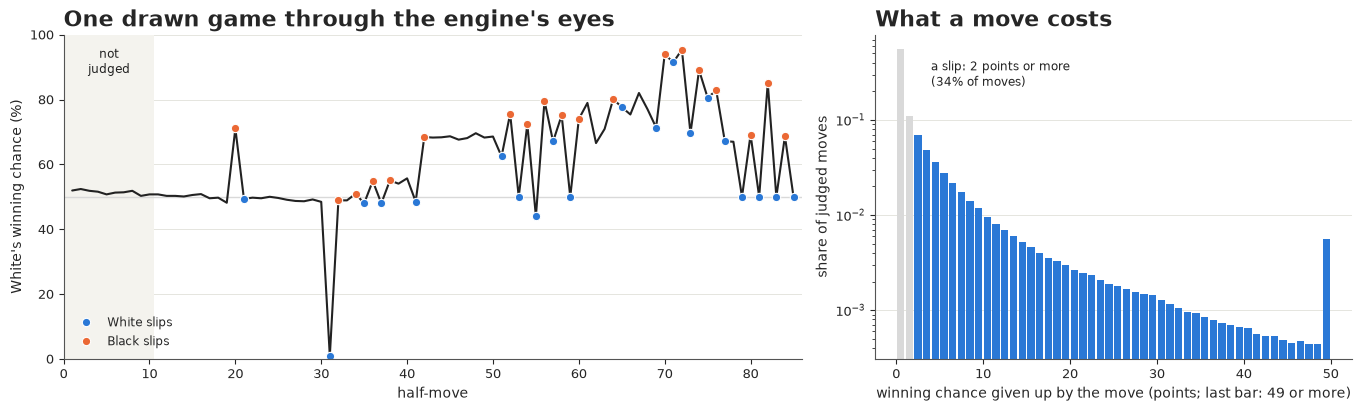

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.0), gridspec_kw={"width_ratios": [1.55, 1]})
ax = axes[0]
gi = int(games.index[games["plies"].between(72, 88) & (games["result"] == "1/2-1/2")][0])      # one game, to show the measure
w = win_chance(games.loc[gi, "evals"])
k = np.arange(1, len(w))
loss = np.where(k % 2 == 0, w[:-1] - w[1:], w[1:] - w[:-1])
ax.axhline(50, color=LIGHT, lw=1)
ax.plot(np.arange(1, len(w) + 1), w, color=INK, lw=1.5)
for side, colour, label in ((0, BLUE, "White slips"), (1, ORANGE, "Black slips")):
    m_ = (k % 2 == side) & (loss >= SLIP) & (k >= FIRST_PLY)
    ax.plot(k[m_] + 1, w[1:][m_], "o", ms=6, color=colour, mec="white", mew=0.8, label=label)
ax.axvspan(0, FIRST_PLY + 0.5, color="#f4f3ee", lw=0)
ax.text(FIRST_PLY / 2 + 0.3, 96, "not\njudged", ha="center", va="top", fontsize=8.5, color=INK)
ax.set_ylim(0, 100)
ax.set_xlim(0, len(w) + 1)
ax.set_xlabel("half-move")
ax.set_ylabel("White's winning chance (%)")
ax.legend(frameon=False, fontsize=8.5, loc="lower left")
ax.set_title("One drawn game through the engine's eyes", loc="left")
tidy(ax)

ax = axes[1]
edges = np.arange(0, 51, 1.0)
h = np.histogram(np.minimum(mv["loss"], 49.9), edges)[0] / len(mv)
ax.bar(edges[:-1] + 0.5, h, width=0.84, color=np.where(edges[:-1] >= SLIP, BLUE, LIGHT))
ax.set_yscale("log")
ax.set_xlabel("winning chance given up by the move (points; last bar: 49 or more)")
ax.set_ylabel("share of judged moves")
ax.text(4, 0.3, f"a slip: 2 points or more\n({mv['slip'].mean():.0%} of moves)", fontsize=8.8, color=INK, va="center")
ax.set_title("What a move costs", loc="left")
tidy(ax);

The left panel is one game, a draw: White's winning chance after each half-move, with a dot for every
slip by the side that had just moved. The right panel is every judged move of the file, two million of
them, on a logarithmic scale: more than half cost less than a point, a third are slips, and one in
eleven costs ten points or more.

The cut at two points was chosen by looking at the fitting accounts. Low cuts separated marked from
unmarked accounts better than a cut at ten points, the size of error that players call a mistake.
Strong players avoid mistakes too. What they do not avoid, over thirty moves, is drift.

> **The choice.** The unit is the account, the label is the platform's mark, and the outcome is the
> slip: a move, from the sixth on, that gives up two points or more of winning chance. *Rejected:* the
> "rules infraction" tag as a label (the accounts it points at kept playing), and a cut at ten points
> (it separates the marked accounts less well). *Considered:* the closed accounts as a third group; we
> cannot tell why they closed. *What would change our mind:* marks with a date and a reason. A mark for
> boosting, and a mark given in 2020 for games of 2019, both sit in our label as noise.

## 2 · Strength: how good is this account, at the time of the game?

Expectation needs a rating. We compare three candidates for the strength of an account when it sat
down to a game.

**The first rating of the window** is one number per account: the rating it had when its first game of
the six months began. A rating list that is published and then used for months works like this, and
so does any table with one row per account. **The published rating
before each game** is the site's own, updated after every game (the files carry Glicko-2 ratings).
**A random walk** is ours: the strength of account $a$ in fortnight $p$ is its strength in the previous
fortnight plus a step, and results depend on it through a logistic curve,

$$ s_{a,0} \sim \mathcal{N}(\mu, \sigma_0), \qquad s_{a,p} = s_{a,p-1} + \tau\,\epsilon_{a,p}, \qquad
P(\text{win}) = \operatorname{logit}^{-1}\big((s_{a,p} - r_{\text{opp}})/c\big). $$

Here $r_{\text{opp}}$ is the opponent's published rating, taken as known, and $c$ is the scale of the
curve, which Elo's formula fixes at $400/\ln 10 \approx 174$ points and which we estimate. A draw
counts as half a win and half a loss. Unlike the published rating, the walk looks both ways in time,
which is legitimate here: a review happens after the fact.

The check is the same for all three: we hold back a fifth of the result cells and score each
candidate's predictions of them.

One practical turn comes first. The walk has 13 strengths for each of 2,541 accounts: 33,000 unknowns.
Our first run of that model in PyMC ran for six minutes and then exceeded the memory budget of this
notebook without finishing. But given the four hyperparameters the accounts are independent, and the
posterior of one account's strengths is close to Gaussian. So we fit the model in PyMC on 250
accounts, to learn $\mu$, $\sigma_0$, $\tau$ and $c$, and then compute every account's posterior mode
and curvature with a few Newton steps: a smoother, in 15 lines of NumPy. The 250 accounts are where
we check that the shortcut costs nothing.

In [6]:
res["a"] = code.get_indexer(res["account"])
res["score"] = res["wins"] + 0.5 * res["draws"]
res["held_out"] = rng.random(len(res)) < 0.2            # cells of results kept back to compare the ratings
ELO_SCALE = 400 / np.log(10) / 100                      # Elo's logistic scale, in hundreds of points
N_SUB = 250
sub = np.sort(rng.choice(A, N_SUB, replace=False))
fit_cells = res[~res["held_out"] & res["a"].isin(sub)]
sub_idx = np.searchsorted(sub, fit_cells["a"].to_numpy())

t0 = time.time()
with pm.Model(coords={"account": acc["account"].to_numpy()[sub], "step": np.arange(1, P)}) as walk:
    mu = pm.Normal("mu", 16.0, 2.0)                     # strengths in hundreds of rating points
    sd_start = pm.HalfNormal("sd_start", 3.0)
    tau = pm.HalfNormal("tau", 0.5)                     # drift per two weeks
    scale = pm.LogNormal("scale", np.log(ELO_SCALE), 0.25)
    start = pm.Normal("start", mu, sd_start, dims="account")
    steps = pm.Normal("steps", 0.0, 1.0, dims=("account", "step"))
    s = pt.concatenate([start[:, None], start[:, None] + tau * pt.cumsum(steps, axis=1)], axis=1)
    eta = (s[sub_idx, fit_cells["period"].to_numpy()] - fit_cells["opp_elo"].to_numpy() / 100) / scale
    pm.Potential("loglik", (fit_cells["score"].to_numpy() * pt.log(pm.math.sigmoid(eta))
                            + (fit_cells["n"] - fit_cells["score"]).to_numpy() * pt.log1p(-pm.math.sigmoid(eta))).sum())
    idata_walk = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
print(f"random-walk strengths, {N_SUB} accounts, {fit_cells['n'].sum():,} games: {diagnostics(idata_walk)} "
      f"({time.time() - t0:.0f} s)")
print(az.summary(idata_walk, var_names=["mu", "sd_start", "tau", "scale"], round_to=3)[["mean", "sd", "ess_bulk", "r_hat"]].to_string())
pw = az.extract(idata_walk)
paths = pw["start"].to_numpy()[:, None, :] + np.concatenate(
    [np.zeros((N_SUB, 1, pw.sizes["sample"])),
     pw["tau"].to_numpy() * np.cumsum(pw["steps"].transpose("account", "step", "sample").to_numpy(), axis=1)], axis=1)
PM_MEAN, PM_SD = 100 * paths.mean(-1), 100 * paths.std(-1)
HYPER = {k: float(idata_walk.posterior[k].mean()) for k in ("mu", "sd_start", "tau", "scale")}
del idata_walk, pw, paths


def smooth(cells, hyper, n_iter=40):
    """Mode and sd of each account's 13 strengths given the walk's hyperparameters (Newton steps), in points."""
    q = np.zeros((P, P))
    i = np.arange(P - 1)
    for r_, c_, v in ((i, i, 1), (i + 1, i + 1, 1), (i, i + 1, -1), (i + 1, i, -1)):
        q[r_, c_] += v / hyper["tau"] ** 2
    q[0, 0] += 1 / hyper["sd_start"] ** 2
    key = cells["a"].to_numpy() * P + cells["period"].to_numpy()
    opp, n, score = cells["opp_elo"].to_numpy() / 100, cells["n"].to_numpy(float), cells["score"].to_numpy()
    theta = np.full((A, P), hyper["mu"])
    for _ in range(n_iter):
        e = special.expit((theta.ravel()[key] - opp) / hyper["scale"])
        grad = np.bincount(key, (score - n * e) / hyper["scale"], A * P).reshape(A, P)
        info = np.bincount(key, n * e * (1 - e) / hyper["scale"] ** 2, A * P).reshape(A, P)
        hess = q[None] + info[:, :, None] * np.eye(P)[None]
        theta = theta + np.clip(np.linalg.solve(hess, (grad - (theta - hyper["mu"]) @ q)[:, :, None])[:, :, 0], -1.5, 1.5)
    return 100 * theta, 100 * np.sqrt(np.diagonal(np.linalg.inv(hess), axis1=1, axis2=2))


s_check, sd_check = smooth(res[~res["held_out"]], HYPER)
gap = s_check[sub] - PM_MEAN
print(f"\nsmoother against PyMC on the {N_SUB} accounts: root mean square difference {np.sqrt((gap ** 2).mean()):.1f} points, "
      f"largest {np.abs(gap).max():.0f}; ratio of the two standard deviations, median {np.median(sd_check[sub] / PM_SD):.2f}")

held = res[res["held_out"]]
rival = {"first rating of the window": acc["elo_first"].to_numpy()[held["a"]],
         "published rating before each game": held["own_elo"].to_numpy(),
         "random-walk strength": s_check[held["a"], held["period"]]}
score_rows = {}
for label, own in rival.items():
    e = np.clip(special.expit((own - held["opp_elo"]) / 100 / HYPER["scale"]), 1e-6, 1 - 1e-6)
    log_score = (held["score"] * np.log(e) + (held["n"] - held["score"]) * np.log(1 - e)).sum() / held["n"].sum()
    score_rows[label] = {"log score per game": log_score, "expected score": (e * held["n"]).sum() / held["n"].sum()}
print(f"\n{held['n'].sum():,} held-out games; actual score {held['score'].sum() / held['n'].sum():.4f}")
print(pd.DataFrame(score_rows).T.round(4).to_string())
STRENGTH, STRENGTH_SD = smooth(res, HYPER)             # the hand-over: every account, every period, all results
mv["strength"] = STRENGTH[mv["a"], mv["period"]]
mv["first"] = acc["elo_first"].to_numpy()[mv["a"]]
print(f"\nposterior sd of a strength: median {np.median(STRENGTH_SD):.0f} points")

random-walk strengths, 250 accounts, 113,474 games: divergences 0, max r_hat 1.011, min ESS 320 (29 s)
            mean     sd  ess_bulk  r_hat
mu        16.419  0.152  5948.467  1.002
sd_start   2.291  0.111  3385.943  1.000
tau        0.235  0.023   319.697  1.011
scale      2.208  0.025  3981.631  1.001



smoother against PyMC on the 250 accounts: root mean square difference 1.5 points, largest 8; ratio of the two standard deviations, median 1.00

294,112 held-out games; actual score 0.5124
                                   log score per game  expected score
first rating of the window                    -0.6897          0.4552
published rating before each game             -0.6151          0.5086
random-walk strength                          -0.6174          0.5121



posterior sd of a strength: median 44 points


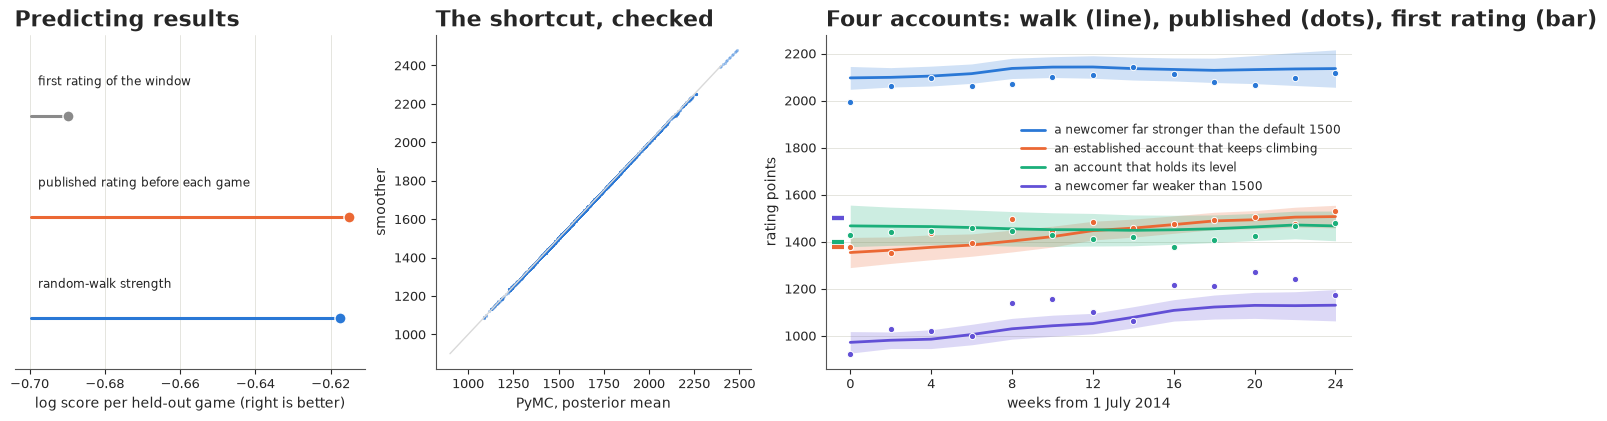

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.1), gridspec_kw={"width_ratios": [1.0, 0.9, 1.5]})
ax = axes[0]
score_tab = pd.DataFrame(score_rows).T
for i, (label, colour) in enumerate(zip(score_tab.index, (MUTED, ORANGE, BLUE))):
    ax.plot([score_tab["log score per game"].min() - 0.01, score_tab.loc[label, "log score per game"]], [i, i], color=colour, lw=2.2)
    ax.plot(score_tab.loc[label, "log score per game"], i, "o", ms=8, color=colour, mec="white", mew=1)
    ax.text(score_tab["log score per game"].min() - 0.008, i - 0.3, label, fontsize=8.8, color=INK)
ax.set_yticks([])
ax.set_ylim(2.5, -0.8)
ax.set_xlabel("log score per held-out game (right is better)")
ax.set_title("Predicting results", loc="left")
tidy(ax, grid="x")
ax.spines["left"].set_visible(False)

ax = axes[1]
ax.plot([900, 2400], [900, 2400], color=LIGHT, lw=1)
ax.scatter(PM_MEAN.ravel(), s_check[sub].ravel(), s=5, color=BLUE, alpha=0.4, lw=0)
ax.set_xlabel("PyMC, posterior mean")
ax.set_ylabel("smoother")
ax.set_title("The shortcut, checked", loc="left")
tidy(ax, grid=None)

ax = axes[2]
cells = res.assign(w_own=res["own_elo"] * res["n"]).groupby(["a", "period"])[["w_own", "n"]].sum()
pub = (cells["w_own"] / cells["n"]).unstack().reindex(range(A)).to_numpy()            # published rating, period means
active = np.isfinite(pub).sum(1)
change = STRENGTH[:, -1] - acc["elo_first"].to_numpy()
whole = (active == P) & (acc["marked"].to_numpy() == 0)
new, climb = (acc["elo_first"] == 1500).to_numpy(), STRENGTH[:, -1] - STRENGTH[:, 0]
picks = [("a newcomer far stronger than the default 1500", np.where(whole & new, change, -np.inf).argmax(), BLUE),
         ("an established account that keeps climbing", np.where(whole & ~new, climb, -np.inf).argmax(), ORANGE),
         ("an account that holds its level", np.where(whole & ~new & (acc["elo_first"] < 1500), -np.abs(climb), -np.inf).argmax(), AQUA),
         ("a newcomer far weaker than 1500", np.where(whole & new, -change, -np.inf).argmax(), VIOLET)]
x = np.arange(P)
for label, a_, colour in picks:
    ax.fill_between(x, STRENGTH[a_] - 1.64 * STRENGTH_SD[a_], STRENGTH[a_] + 1.64 * STRENGTH_SD[a_], color=colour, alpha=0.22, lw=0)
    ax.plot(x, STRENGTH[a_], color=colour, lw=2, label=label)
    ax.plot(x, pub[a_], "o", ms=4.5, color=colour, mec="white", mew=0.7)
    ax.plot([-0.45, -0.15], [acc["elo_first"][a_]] * 2, color=colour, lw=3, solid_capstyle="butt")
ax.set_xlim(-0.6, P - 0.6)
ax.set_xticks(range(0, P, 2), [f"{2 * i}" for i in range(0, P, 2)])
ax.set_xlabel("weeks from 1 July 2014")
ax.set_ylabel("rating points")
ax.legend(frameon=False, fontsize=8.5, loc="center right", bbox_to_anchor=(1.0, 0.63))
ax.set_title("Four accounts: walk (line), published (dots), first rating (bar)", loc="left")
tidy(ax);

The fit on 250 accounts is clean: no divergences, and the slowest parameter, $\tau$, has an effective
sample of about 300. A typical account moves by about 23 points a fortnight, and the scale of the
curve is about 220 points where Elo's formula has 174: against published ratings, a rating gap is
worth less than the formula says. The middle panel checks the shortcut. Across the 250 accounts the
smoother and PyMC differ by 1.5 points in root mean square and by 8 at most.

On the held-out games (left panel) **the first rating fails**. Its log score is -0.69 per game, the
score of a coin, and it expects these accounts to score 45.5% where they score 51.2%. The reason is
printed in part 1: 46% of the sampled accounts begin the window on exactly 1500, the rating Lichess
gives an account before it has played. Their first rating is not stale. It is empty.

Then a surprise: **the site's own rating beats our walk** at predicting results, narrowly (-0.615
against -0.617). We had expected the opposite. The right panel shows why. The published rating moves
after every game; our strength moves once a fortnight and is pulled towards its neighbours, so it
trails an account whose rating keeps moving (the violet one).

So which do we keep? For predicting results, the published rating. Our chain needs the strength that
best explains the *moves*, and part 3 puts the same three candidates to that test. We carry the walk
forward, with its posterior standard deviation of about 44 points, and settle the question there.

> **The choice.** Strength is a random walk over fortnights, fitted in PyMC on 250 accounts and
> extended to all of them by a smoother. *Rejected:* one rating per account (no better than a coin on
> held-out games), and all 33,000 strengths in one PyMC model (too slow and too large for a notebook).
> *Considered:* the published rating before each game. It predicts results a little better than the
> walk, and we keep the walk only because it predicts moves better (part 3). *What would change our
> mind:* a walk with a step per game, or with heavier-tailed steps, ought to close the gap on results.
> If it did not, this link belongs to the platform's rating.

## 3 · Move quality: how often should this player slip, here?

The second link predicts the outcome of every move: slip or no slip. The first model is the one the
z-score tradition starts from, in which the chance of a slip depends on the player's strength alone:
$\operatorname{logit} P(\text{slip}) = \alpha + \beta\,(s - 1600)/200$. With 1.25 million moves by
the fitting accounts we do not need them one by one. Moves by players within 100 points of one another
are counted together, which leaves 18 rows and a binomial likelihood, the device E120 used for its
317,000 calls.

In [8]:
SITUATION = ["bef", "opp", "phase", "in_check", "recapture"]
DECIDED = [0, 1, 9, 10]                            # winning chance under 5 or over 95 before the move
STRENGTH_BANDS = [0, 1300, 1500, 1700, 1900, 3000]
fit_mv = mv[mv["train"]]


def fit_moves(kind):
    """P(slip) for 'strength only', 'position, one slope' or 'position' (its own slope where the game is decided).
    Moves are counted in cells, so the likelihood is binomial. Returns the posterior means."""
    keys = ["r_bin"] + (SITUATION if kind != "strength only" else [])
    agg = (fit_mv.assign(r_bin=np.round(fit_mv["strength"] / 100)).groupby(keys)
           .agg(n=("slip", "size"), y=("slip", "sum"), r=("strength", "mean")).reset_index())
    x = (agg["r"].to_numpy() - 1600) / 200
    with pm.Model(coords={"before": BEF_LABELS, "opp_gave": OPP_LABELS, "captures": PHASE_LABELS}):
        slope = pm.Normal("slope", 0.0, 0.5)                               # per 200 points of strength
        if kind == "strength only":
            level = pm.Normal("level", -0.7, 1.5)
            eta = level + slope * x
        else:
            situation = pm.Normal("situation", -0.7, 1.5, dims=("before", "opp_gave"))
            s_phase = pm.HalfNormal("s_phase", 0.5)
            phase = pm.ZeroSumNormal("phase", sigma=s_phase, dims="captures")
            check = pm.Normal("check", 0.0, 1.0)
            recapture = pm.Normal("recapture", 0.0, 1.0)
            slope_x = slope * x
            if kind == "position":
                slope_decided = pm.Normal("slope_decided", 0.0, 0.5)         # the slope where the game is decided
                slope_x = pt.switch(np.isin(agg["bef"].to_numpy(), DECIDED), slope_decided, slope) * x
            eta = (situation[agg["bef"].to_numpy(), agg["opp"].to_numpy()] + phase[agg["phase"].to_numpy()]
                   + check * agg["in_check"].to_numpy() + recapture * agg["recapture"].to_numpy() + slope_x)
        pm.Binomial("y", n=agg["n"].to_numpy(), logit_p=eta, observed=agg["y"].to_numpy())
        idata = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
    post = {v: idata.posterior[v].mean(("chain", "draw")).to_numpy() for v in idata.posterior.data_vars}
    post.setdefault("slope_decided", post["slope"])
    print(f"{kind}: {len(agg):,} cells, {diagnostics(idata)}; slope per 200 points {post['slope']:.3f} "
          f"(sd {float(idata.posterior['slope'].std()):.3f})" + (f", where the game is decided {post['slope_decided']:.3f}"
                                                                 if kind == "position" else ""))
    return post


def slip_prob(frame, rating, post):
    """Plug-in probability of a slip for each move in frame, with the rating taken from the named column."""
    x = (frame[rating].to_numpy() - 1600) / 200
    if "situation" not in post:
        return special.expit(post["level"] + post["slope"] * x)
    eta = np.where(np.isin(frame["bef"].to_numpy(), DECIDED), post["slope_decided"], post["slope"]) * x
    return special.expit(eta + post["situation"][frame["bef"].to_numpy(), frame["opp"].to_numpy()]
                         + post["phase"][frame["phase"].to_numpy()] + post["check"] * frame["in_check"].to_numpy()
                         + post["recapture"] * frame["recapture"].to_numpy())


def game_scores(frame, p):
    """Per account-game: judged moves, slips, expected slips and their variance if moves were independent."""
    d = pd.DataFrame({"a": frame["a"].to_numpy(), "g": frame["g"].to_numpy(), "o": frame["slip"].to_numpy(), "e": p,
                      "v": p * (1 - p), "dec": np.isin(frame["bef"].to_numpy(), DECIDED)})
    out = (d.groupby(["a", "g"]).agg(n=("o", "size"), o=("o", "sum"), e=("e", "sum"), v=("v", "sum"), decided=("dec", "mean"))
           .reset_index())
    out["z"] = (out["e"] - out["o"]) / np.sqrt(out["v"])
    out["train"] = acc["train"].to_numpy()[out["a"]]
    return out


M_PLAIN = fit_moves("strength only")
mv["p_plain"] = slip_prob(mv, "strength", M_PLAIN)
fit_mv = mv[mv["train"]]
band = pd.cut(fit_mv["strength"], STRENGTH_BANDS)
print("slip rate by strength band, observed and predicted:")
print(fit_mv.groupby(band, observed=True).agg(moves=("slip", "size"), observed=("slip", "mean"),
                                              predicted=("p_plain", "mean")).round(3).T.to_string())
gs_plain = game_scores(mv, mv["p_plain"].to_numpy())
print(f"\n{len(gs_plain):,} account-games, {gs_plain['n'].median():.0f} judged moves in the median one; z of a game against the share "
      f"of its moves made in decided positions: correlation {np.corrcoef(gs_plain['z'], gs_plain['decided'])[0, 1]:.2f}")

strength only: 18 cells, divergences 0, max r_hat 1.001, min ESS 3974; slope per 200 points -0.102 (sd 0.002)
slip rate by strength band, observed and predicted:
strength   (0, 1300]  (1300, 1500]  (1500, 1700]  (1700, 1900]  (1900, 3000]
moves      87080.000    232728.000    412510.000    336153.000    185721.000
observed       0.377         0.369         0.344         0.323         0.293
predicted      0.391         0.365         0.343         0.322         0.295

69,380 account-games, 29 judged moves in the median one; z of a game against the share of its moves made in decided positions: correlation 0.42


### Failure: score whole games with it

By its own check the model is fine. The odds of a slip fall by about a tenth for every 200 points of
strength, and the predicted slip rate is within half a point of the observed one in every band but
the lowest. Had we stopped at the check a regression usually gets, we would have kept it.

The next link needs a score per game, so we computed one: the slips expected minus the slips made,
divided by the standard deviation that count would have if moves were independent (part 4 defines it
properly). It should be related to nothing but the player. Its correlation with the share of the game
played in decided
positions, where the mover's winning chance is under 5% or over 95%, is 0.42. A game that is decided
early looks brilliant, for both players: when a game is won or lost there is little winning chance
left to give up. Lichess warns of exactly this about its accuracy score: "protracted lopsided endgames
can increase the accuracy score". This is the orange arrow of the route map. The model has no idea
what a position is.

### The position, from what the file carries

No engine runs in this notebook and the moves are not in the file, so "how hard is this position" has
to be built from what is known before the move is played. We use five things: the mover's winning
chance; how much winning chance the opponent's last move gave away (a position that has just changed
sharply holds something to find, or to miss); the number of captures so far, as a clock for the phase
of the game; whether the mover is in check, which leaves few legal moves; and whether the opponent has
just captured, which often makes the reply obvious. The first two enter as a table of 11 by 5
situations with a level each, the others as shifts. A first version with one slope for strength has a
flaw, shown below, so the model we keep has two: one where the game is open, one where it is decided.

In [9]:
t0 = time.time()
M_ONE, M_POS = fit_moves("position, one slope"), fit_moves("position")
print(f"({time.time() - t0:.0f} s)")
mv["p_one"], mv["p_pos"] = slip_prob(mv, "strength", M_ONE), slip_prob(mv, "strength", M_POS)
fit_mv = mv[mv["train"]]
cal = fit_mv.groupby(["bef", "opp"]).agg(n=("slip", "size"), observed=("slip", "mean"), plain=("p_plain", "mean")).reset_index()
cal = cal[cal["n"] >= 200]
print(f"\nslip rate in the {len(cal)} situations with 200 moves or more: observed from {cal['observed'].min():.2f} to "
      f"{cal['observed'].max():.2f}; the strength-only model predicts {cal['plain'].min():.2f} to {cal['plain'].max():.2f}")
print("effects on the logit of a slip: captures so far", dict(zip(PHASE_LABELS, np.round(M_POS["phase"], 2).tolist())),
      "| in check", round(float(M_POS["check"]), 2), "| can recapture", round(float(M_POS["recapture"]), 2))
by_r = (fit_mv.assign(band=pd.cut(fit_mv["strength"], STRENGTH_BANDS), decided=np.isin(fit_mv["bef"], DECIDED))
        .groupby(["decided", "band"], observed=True)
        .agg(observed=("slip", "mean"), one_slope=("p_one", "mean"), two_slopes=("p_pos", "mean")).round(3))
print("\nslip rate by strength band, where the game is open (False) and where it is decided (True):")
print(by_r.to_string())
gs = game_scores(mv, mv["p_pos"].to_numpy())
print(f"\nz of a game against its share of decided positions, position model: correlation "
      f"{np.corrcoef(gs['z'], gs['decided'])[0, 1]:.2f}")
print("\nlog score per move of the position model, by the rating it is given:")
far = (fit_mv["strength"] - fit_mv["published"]).abs() > 150
for label, col in (("random-walk strength", "strength"), ("published rating before the game", "published"),
                   ("first rating of the window", "first")):
    p = np.clip(slip_prob(fit_mv, col, M_POS), 1e-9, 1 - 1e-9)
    ll = np.where(fit_mv["slip"], np.log(p), np.log1p(-p))
    print(f"  {label}: {ll.mean():.4f}; on the {far.mean():.1%} of moves where walk and published rating are more than 150 "
          f"points apart: {ll[far].mean():.4f}")
print(f"a strength that is off by its posterior sd ({np.median(STRENGTH_SD):.0f} points) moves the logit of a slip by "
      f"{abs(M_POS['slope']) * np.median(STRENGTH_SD) / 200:.3f}")

position, one slope: 11,819 cells, divergences 0, max r_hat 1.006, min ESS 4657; slope per 200 points -0.129 (sd 0.002)


position: 11,819 cells, divergences 0, max r_hat 1.005, min ESS 4710; slope per 200 points -0.134 (sd 0.002), where the game is decided -0.069
(17 s)

slip rate in the 47 situations with 200 moves or more: observed from 0.00 to 0.57; the strength-only model predicts 0.33 to 0.35
effects on the logit of a slip: captures so far {'0-2': -0.1, '3-5': 0.01, '6-9': 0.08, '10-14': 0.06, '15 or more': -0.04} | in check -0.75 | can recapture -0.36

slip rate by strength band, where the game is open (False) and where it is decided (True):
                      observed  one_slope  two_slopes
decided band                                         
False   (0, 1300]        0.462      0.461       0.463
        (1300, 1500]     0.422      0.420       0.421
        (1500, 1700]     0.383      0.384       0.384
        (1700, 1900]     0.351      0.352       0.351
        (1900, 3000]     0.314      0.312       0.311
True    (0, 1300]        0.107      0.118       0.109
        (1300, 1500]     0.121   


z of a game against its share of decided positions, position model: correlation 0.05

log score per move of the position model, by the rating it is given:
  random-walk strength: -0.5825; on the 4.4% of moves where walk and published rating are more than 150 points apart: -0.5605
  published rating before the game: -0.5829; on the 4.4% of moves where walk and published rating are more than 150 points apart: -0.5649
  first rating of the window: -0.5850; on the 4.4% of moves where walk and published rating are more than 150 points apart: -0.5699
a strength that is off by its posterior sd (44 points) moves the logit of a slip by 0.029


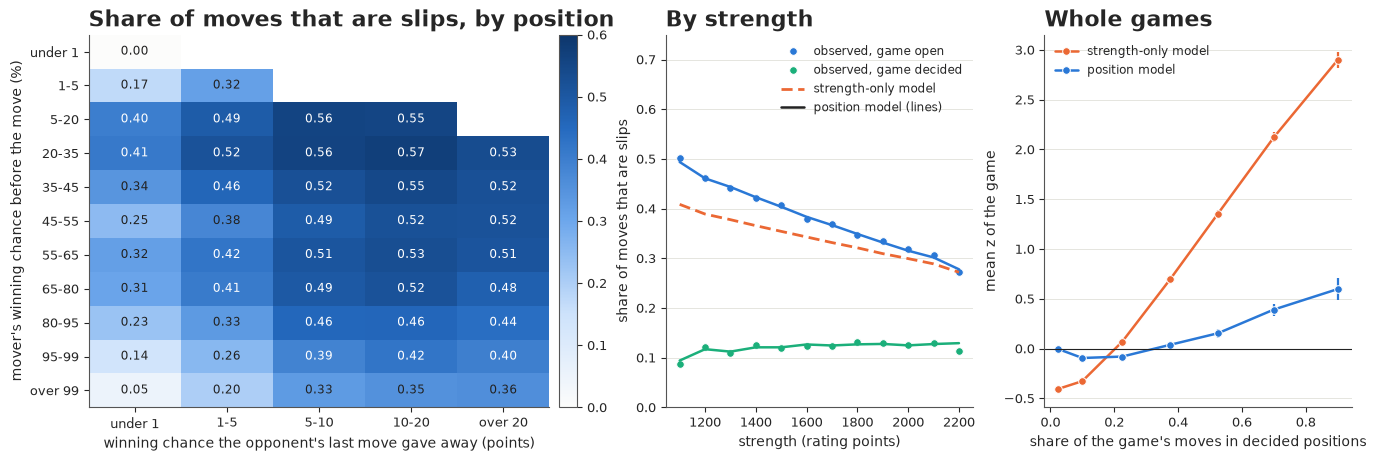

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.5), gridspec_kw={"width_ratios": [1.35, 0.9, 0.9]})
ax = axes[0]
heat = fit_mv.groupby(["bef", "opp"])["slip"].agg(["mean", "size"]).reset_index()
grid_ = np.full((11, 5), np.nan)
grid_[heat["bef"], heat["opp"]] = np.where(heat["size"] >= 200, heat["mean"], np.nan)
im = ax.imshow(grid_, aspect="auto", cmap=SEQ, vmin=0, vmax=0.6)
for (i, j), v in np.ndenumerate(grid_):
    if np.isfinite(v):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5, color="white" if v > 0.38 else INK)
ax.set_xticks(range(5), OPP_LABELS)
ax.set_yticks(range(11), BEF_LABELS)
ax.set_xlabel("winning chance the opponent's last move gave away (points)")
ax.set_ylabel("mover's winning chance before the move (%)")
ax.grid(False)
fig.colorbar(im, ax=ax, pad=0.02)
ax.set_title("Share of moves that are slips, by position", loc="left")

ax = axes[1]
hundred = fit_mv.assign(r_bin=np.clip(np.round(fit_mv["strength"] / 100) * 100, 1100, 2200), decided=np.isin(fit_mv["bef"], DECIDED))
by = hundred.groupby(["decided", "r_bin"]).agg(observed=("slip", "mean"), position=("p_pos", "mean"))
for dec, colour, label in ((False, BLUE, "open"), (True, AQUA, "decided")):
    d = by.loc[dec]
    ax.plot(d.index, d["observed"], "o", ms=5.5, color=colour, mec="white", mew=0.7, label=f"observed, game {label}")
    ax.plot(d.index, d["position"], color=colour, lw=1.8)
ax.plot(by.loc[False].index, hundred.groupby("r_bin")["p_plain"].mean(), color=ORANGE, lw=2, ls=(0, (4, 2)), label="strength-only model")
ax.plot([], [], color=INK, lw=1.8, label="position model (lines)")
ax.set_xlabel("strength (rating points)")
ax.set_ylabel("share of moves that are slips")
ax.legend(frameon=False, fontsize=8.3, loc="upper right")
ax.set_ylim(0, 0.75)
ax.set_title("By strength", loc="left")
tidy(ax)

ax = axes[2]
share_bins = np.array([0, 0.05, 0.15, 0.3, 0.45, 0.6, 0.8, 1.0001])
mid = (share_bins[:-1] + share_bins[1:]) / 2
for frame, colour, label in ((gs_plain, ORANGE, "strength-only model"), (gs, BLUE, "position model")):
    which = np.searchsorted(share_bins, frame["decided"], side="right") - 1
    mean, se = frame.groupby(which)["z"].mean().reindex(range(7)), frame.groupby(which)["z"].sem().reindex(range(7))
    ax.vlines(mid, mean - 2 * se, mean + 2 * se, color=colour, lw=1.6)
    ax.plot(mid, mean, "o-", ms=5.5, color=colour, mec="white", mew=0.7, lw=1.8, label=label)
ax.axhline(0, color=INK, lw=0.8)
ax.set_xlabel("share of the game's moves in decided positions")
ax.set_ylabel("mean z of the game")
ax.legend(frameon=False, fontsize=8.3, loc="upper left")
ax.set_title("Whole games", loc="left")
tidy(ax);

The left panel is the reason the first model fails. The share of moves that are slips runs from zero,
in a lost position after a quiet move, where nothing is left to lose, to 57%, in a worse position just
after the opponent has erred. The strength-only model predicts between 33% and 35% for every one of
these situations. Positions differ far more than players do: across the whole range of strength in the
file the slip rate in open games goes from 50% to under 30% (middle panel), and the position moves it
from 0 to 57.

The printed table shows the flaw of the one-slope version. In decided positions it has slips becoming
rarer with strength, from 11.8% in the lowest band to 11.5% in the highest, and they become more
frequent, from 10.7% to 12.6%. With a slope of its own for decided positions the model follows both
curves (the lines of the middle panel). Being in check halves the odds of a slip, a recapture cuts
them by a third, and the phase of the game adds little.

The right panel repeats the check that sent us back. With the position in the model, the correlation
between a game's score and its share of decided positions falls from 0.42 to 0.05. The blue line is
not perfectly flat: games that are almost entirely decided still score about half a standard deviation
too well.

**The rating question, settled on moves.** The last lines of the output give the same position model
each of the three ratings of part 2 and score its predictions move by move. The walk is best (-0.5825),
the published rating second (-0.5829) and the first rating last (-0.5850). The differences are small
because strength is a small part of this model; on 1.25 million moves they are not noise. On the 4% of
moves where the walk and the published rating are more than 150 points apart the gap is ten times as
large (-0.5605 against -0.5649). A likely reason is that the published rating of a new account spends
its first games far from the truth, and the walk, which also sees the later results, does not.

One more number closes the hand-over. A strength that is wrong by its posterior standard deviation, 44
points, moves the logit of a slip by 0.03, so we pass on posterior means and lose nothing by it.

> **The choice.** A slip is binomial given strength and the position: 55 situations, the phase, check,
> recapture, and a slope for strength that differs between open and decided games. *Rejected:* strength
> alone (its game scores track how early a game is decided), and one slope for all positions (the
> wrong sign where the game is decided). *Considered:* the mover's own previous slip as a predictor.
> Slips do come in runs, as part 4 shows, but a model that expects clean play from whoever has just
> played cleanly expects the very pattern we are looking for. *What would change our mind:* the
> positions themselves. With the moves and an engine one could weigh every alternative, as Regan and
> Haworth do with "the evaluations of all possible moves".

## 4 · Surprise: how unusual is one game?

Take one account in one game, with $n$ judged moves. The model gives each move its chance $p_i$ of
being a slip. If moves were independent, the number of slips $O$ would have mean $E = \sum p_i$ and
variance $V = \sum p_i (1 - p_i)$, and

$$ z = \frac{E - O}{\sqrt{V}} $$

would be close to a standard normal, positive when the player slipped less often than expected. This
is the z-score of the question, for one game. Its first check is the easiest there is: does it have a
standard deviation of 1?

In [11]:
gt = gs[gs["train"]]
tail = lambda z, k: f"{(z > k).mean():.4f}"
print(f"if moves were independent, z would be standard normal: sd 1, {stats.norm.sf(2):.4f} above 2, {stats.norm.sf(3):.4f} above 3")
print(f"observed on the fitting accounts: sd {gt['z'].std():.2f}, {tail(gt['z'], 2)} above 2, {tail(gt['z'], 3)} above 3")

one = gt.groupby("a").sample(1, random_state=RANDOM_SEED)                 # one game per account: independent games
moves_one = fit_mv.merge(one[["a", "g"]].assign(k=np.arange(len(one))), on=["a", "g"])
moves_one = (moves_one.assign(logit=np.round(special.logit(moves_one["p_pos"]) * 4) / 4)     # same logit to a quarter: one row
             .groupby(["k", "logit"]).agg(n=("slip", "size"), y=("slip", "sum")).reset_index())
t0 = time.time()
with pm.Model() as game_model:
    sigma_game = pm.HalfNormal("sigma_game", 0.5)
    u = pm.Normal("u", 0.0, 1.0, shape=len(one))
    pm.Binomial("slips", n=moves_one["n"].to_numpy(), observed=moves_one["y"].to_numpy(),
                logit_p=moves_one["logit"].to_numpy() + sigma_game * u[moves_one["k"].to_numpy()])
    idata_game = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
SIGMA_GAME = float(idata_game.posterior["sigma_game"].mean())
print(f"\ngame effect on {len(one):,} games ({moves_one['n'].sum():,} moves in {len(moves_one):,} rows): {diagnostics(idata_game)} "
      f"({time.time() - t0:.0f} s); sigma_game = {SIGMA_GAME:.3f} (sd {float(idata_game.posterior['sigma_game'].std()):.3f})")
del idata_game
z_game = (gt["e"] - gt["o"]) / np.sqrt(gt["v"] + SIGMA_GAME ** 2 * gt["v"] ** 2)
print(f"z with the game effect: sd {z_game.std():.2f}, {tail(z_game, 2)} above 2, {tail(z_game, 3)} above 3")
v_edges = np.array([0, 2, 3, 4, 5, 6, 7, 8, 9, 10.5, 20])
v_bin = np.searchsorted(v_edges, gt["v"], side="right") - 1
by_v = pd.DataFrame({"games": gt.groupby(v_bin).size(), "V": gt.groupby(v_bin)["v"].mean(), "sd of z": gt.groupby(v_bin)["z"].std()})
by_v["game effect predicts"] = np.sqrt(1 + SIGMA_GAME ** 2 * by_v["V"])
print("\nspread of z by V, the variance of the slip count if moves were independent:")
print(by_v.round(2).T.to_string())
in_order = fit_mv.sort_values(["g", "a", "ply"])
own_last = in_order.groupby(["g", "a"])["slip"].shift(1)             # the same player's previous judged move
runs = (in_order[own_last.notna()]
        .assign(after=np.where(own_last.dropna().astype(bool), "a slip of their own", "a clean move of their own"))
        .groupby("after").agg(moves=("slip", "size"), observed=("slip", "mean"), predicted=("p_pos", "mean")))
print("\nslip rate by what the same player did one move earlier:")
print(runs.round(3).to_string())

if moves were independent, z would be standard normal: sd 1, 0.0228 above 2, 0.0013 above 3
observed on the fitting accounts: sd 1.24, 0.0539 above 2, 0.0051 above 3



game effect on 1,541 games (44,904 moves in 12,619 rows): divergences 0, max r_hat 1.008, min ESS 1085 (18 s); sigma_game = 0.311 (sd 0.017)
z with the game effect: sd 1.00, 0.0198 above 2, 0.0002 above 3

spread of z by V, the variance of the slip count if moves were independent:
                           0        1        2        3        4        5        6        7        8       9
games                 411.00  3426.00  6223.00  6421.00  5802.00  4907.00  4276.00  4204.00  5923.00  405.00
V                       1.57     2.57     3.52     4.49     5.48     6.49     7.49     8.51     9.70   10.64
sd of z                 1.33     1.26     1.25     1.23     1.22     1.24     1.24     1.24     1.23    1.13
game effect predicts    1.07     1.12     1.16     1.20     1.24     1.28     1.31     1.35     1.39    1.43



slip rate by what the same player did one move earlier:
                            moves  observed  predicted
after                                                 
a clean move of their own  798864     0.295      0.311
a slip of their own        413330     0.426      0.391


### Failure: moves are not independent, and the repair we planned fails too

It is 1.24. Games stray from expectation by a quarter more than independent moves allow, and 0.5% of
them lie beyond 3, where the normal puts 0.13%. An analyst who reads z as a standard normal meets a
"three-sigma" game four times as often as promised, before anyone has cheated.

The repair we had planned is the textbook one, a game effect: some days a player is in form, so every
move of a game shares a shift $u_g \sim \mathcal{N}(0, \sigma)$ on the logit scale. We fitted it in
PyMC on one game per account, 1,541 independent games, and found $\sigma \approx 0.31$. Dividing by
the standard deviation that it implies, $\sqrt{V + \sigma^2 V^2}$, brings the standard deviation of
the score to 1.00. That would have passed the check we started with.

The table is the check it does not pass. A shared shift adds variance in proportion to $V^2$, so it
predicts a standard deviation of z that climbs from 1.07 to 1.43 across the table, from games with
little to say to games with a lot. The observed spread does not climb. It is 1.33 for the few games
with least information and between 1.22 and 1.26 almost everywhere else. The game effect has the
right size on average and the wrong shape, and it would have given long, informative games a wider
allowance than they need.

A spread that does not grow with the length of the game is what short-range dependence produces: not
good days and bad days, but slips that come in runs. The last lines of the output show them. After a
slip of their own, players slip again on 43% of moves, where the model expects 39%; after a clean move
they slip on 29.5%, where it expects 31%. So we stop assuming a mechanism and measure the spread: z is
normal with a centre and a standard deviation $\phi(V) = \exp(a + b\,(V - 5)/5)$ that is free to rise
or fall with $V$, fitted in PyMC on the same 1,541 games. The **surprise** of a game is its z,
recentred and divided by the fitted spread.

In [12]:
V_MID = 5.0
with pm.Model() as spread_model:
    centre = pm.Normal("centre", 0.0, 0.5)
    log_phi = pm.Normal("log_phi", 0.0, 0.5)             # log sd of z for a game with V = 5
    tilt = pm.Normal("tilt", 0.0, 0.5)                   # change of the log sd per 5 units of V
    pm.Normal("z", centre, pt.exp(log_phi + tilt * (one["v"].to_numpy() - V_MID) / V_MID), observed=one["z"].to_numpy())
    idata_spread = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
print("spread of z:", diagnostics(idata_spread))
print(az.summary(idata_spread, round_to=3)[["mean", "sd", "eti89_lb", "eti89_ub", "ess_bulk", "r_hat"]].to_string())
SPREAD = tuple(float(idata_spread.posterior[v].mean()) for v in ("centre", "log_phi", "tilt"))
del idata_spread


def surprise(g, spread):
    """z of a game, recentred and divided by the spread that games of its V really have."""
    return (g["z"] - spread[0]) / np.exp(spread[1] + spread[2] * (g["v"] - V_MID) / V_MID)


gs["s"] = surprise(gs, SPREAD)
gt = gs[gs["train"]]
print(f"\nsurprise on all games of the fitting accounts: sd {gt['s'].std():.2f}, {tail(gt['s'], 2)} above 2, {tail(gt['s'], 3)} above 3, "
      f"{tail(-gt['s'], 2)} below -2, {tail(-gt['s'], 3)} below -3")
print("sd of the surprise by V:", gt.groupby(v_bin)["s"].std().round(2).tolist())

spread of z: divergences 0, max r_hat 1.001, min ESS 4010
          mean     sd  eti89_lb  eti89_ub  ess_bulk  r_hat
centre   0.006  0.031    -0.043     0.054  5695.840  1.001
log_phi  0.216  0.019     0.186     0.247  4009.562  1.001
tilt     0.006  0.039    -0.057     0.070  4444.532  1.001

surprise on all games of the fitting accounts: sd 1.00, 0.0197 above 2, 0.0003 above 3, 0.0210 below -2, 0.0010 below -3
sd of the surprise by V: [1.08, 1.02, 1.01, 0.99, 0.99, 1.0, 0.99, 0.99, 0.99, 0.91]


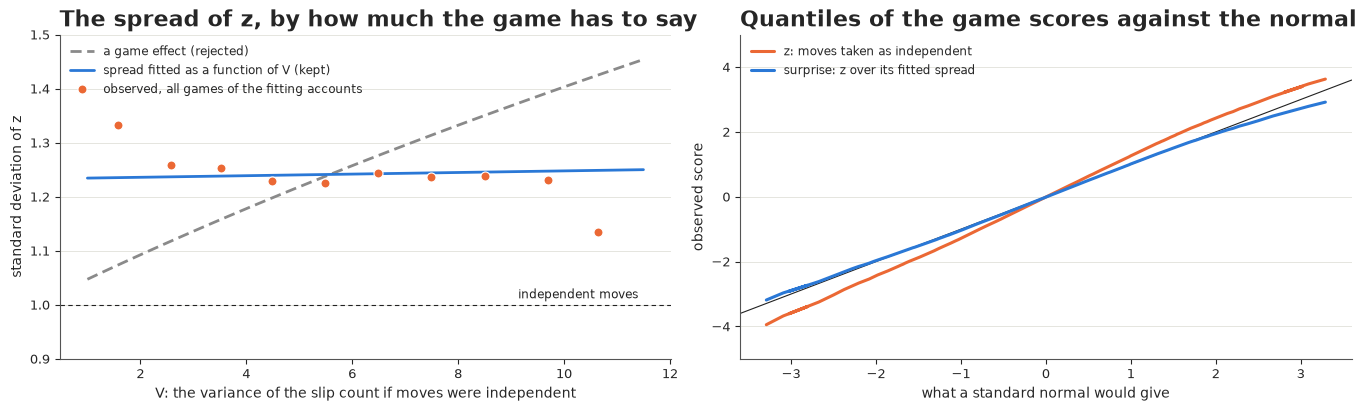

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.0))
ax = axes[0]
vv = np.linspace(1, 11.5, 100)
ax.plot(vv, np.sqrt(1 + SIGMA_GAME ** 2 * vv), color=MUTED, lw=2, ls=(0, (4, 2)), label="a game effect (rejected)")
ax.plot(vv, np.exp(SPREAD[1] + SPREAD[2] * (vv - V_MID) / V_MID), color=BLUE, lw=2, label="spread fitted as a function of V (kept)")
ax.plot(by_v["V"], by_v["sd of z"], "o", ms=6.5, color=ORANGE, mec="white", mew=0.8, label="observed, all games of the fitting accounts")
ax.axhline(1, color=INK, lw=0.8, ls=(0, (4, 3)))
ax.text(11.4, 1.012, "independent moves", ha="right", fontsize=8.5, color=INK)
ax.set_xlabel("V: the variance of the slip count if moves were independent")
ax.set_ylabel("standard deviation of z")
ax.set_ylim(0.9, 1.5)
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax.set_title("The spread of z, by how much the game has to say", loc="left")
tidy(ax)

ax = axes[1]
probs = np.concatenate([[0.0005, 0.001, 0.0025], (np.arange(1, 400) - 0.5) / 399, [0.9975, 0.999, 0.9995]])
nq = stats.norm.ppf(probs)
ax.plot([-3.6, 3.6], [-3.6, 3.6], color=INK, lw=0.8)
ax.plot(nq, np.quantile(gt["z"], probs), color=ORANGE, lw=2.2, label="z: moves taken as independent")
ax.plot(nq, np.quantile(gt["s"], probs), color=BLUE, lw=2.2, label="surprise: z over its fitted spread")
ax.set_xlabel("what a standard normal would give")
ax.set_ylabel("observed score")
ax.set_xlim(-3.6, 3.6)
ax.set_ylim(-5, 5)
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax.set_title("Quantiles of the game scores against the normal", loc="left")
tidy(ax);

The fitted spread is flat: 1.24 at $V = 5$, with a tilt of 0.01 give or take 0.04. In the left panel it
runs through the observed points where the game effect crosses them at an angle, and it misses only
the two ends, a few hundred games out of 42,000. In the right panel the quantiles of the surprise lie
on the diagonal between -2 and 2. Beyond that the upper tail is lighter than the normal (0.03% of
games above 3): a game can go wrong without limit, and can only go right as far as zero slips. For a
detector that looks at the upper tail, the normal errs on the cautious side.

**What a surprising game looks like.** A score hides the thing it summarises, so before going on we
draw it. In the next figure each game is a pair of strips with one cell per judged move. The upper
strip is the model's chance of a slip in that position: darker means harder. The lower strip is what
the move cost: darker means worse.

games of marked accounts: 21% of the fitting accounts' games, 63% of the 200 most surprising


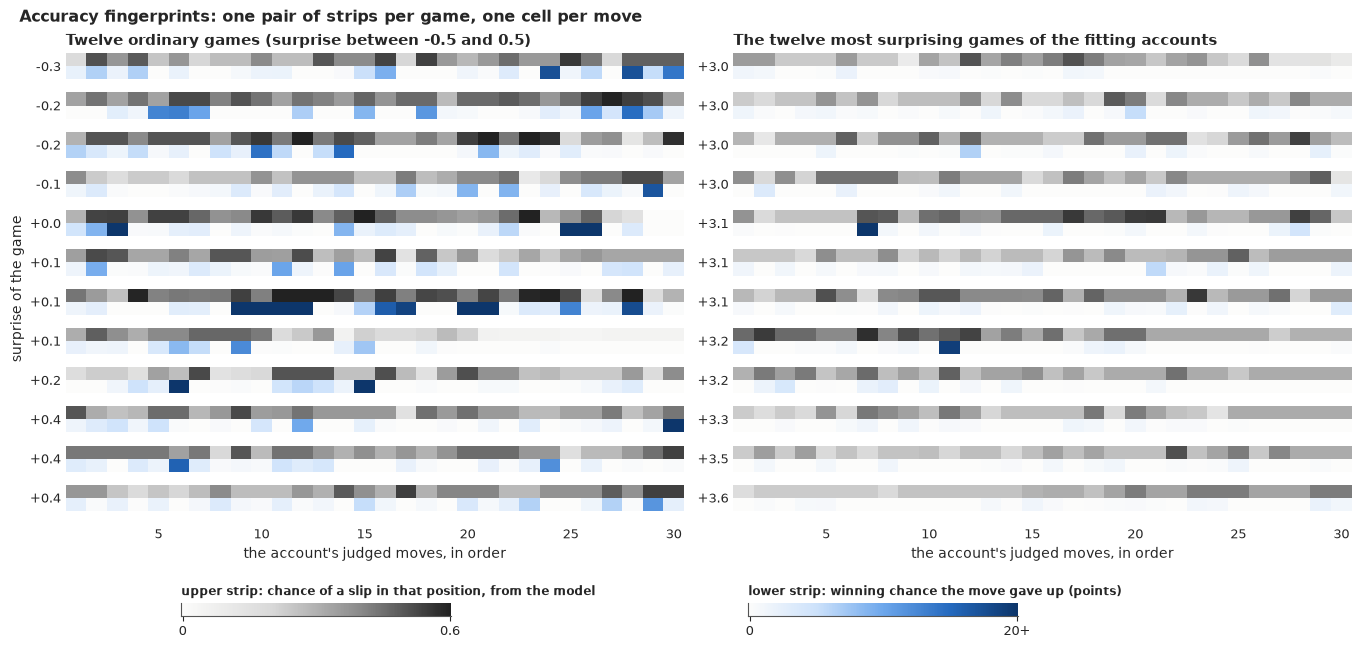

In [14]:
N_SHOW, N_MOVES = 12, 30
long = gt[gt["n"] >= N_MOVES]
blocks = [("Twelve ordinary games (surprise between -0.5 and 0.5)", long[long["s"].abs() < 0.5].sample(N_SHOW, random_state=4)),
          ("The twelve most surprising games of the fitting accounts", long.nlargest(N_SHOW, "s"))]
GREY = LinearSegmentedColormap.from_list("greys", ["#fcfcfb", "#d9d9d9", "#8a8a8a", "#222222"])
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.6))
for ax, (title, chosen) in zip(axes, blocks):
    img = np.ones((3 * N_SHOW, N_MOVES, 4))
    labels = []
    for i, (_, row) in enumerate(chosen.sort_values("s").iterrows()):
        m_ = fit_mv[(fit_mv["a"] == row["a"]) & (fit_mv["g"] == row["g"])].sort_values("ply").head(N_MOVES)
        img[3 * i] = GREY(np.clip(m_["p_pos"].to_numpy() / 0.6, 0, 1))
        img[3 * i + 1] = SEQ(np.clip(m_["loss"].to_numpy() / 20, 0, 1))
        labels.append(f"{row['s']:+.1f}")
    ax.imshow(img, aspect="auto", interpolation="nearest")
    ax.set_yticks(3 * np.arange(N_SHOW) + 0.5, labels)
    ax.set_xticks(range(4, N_MOVES, 5), range(5, N_MOVES + 1, 5))
    ax.set_xlabel("the account's judged moves, in order")
    ax.set_title(title, loc="left", fontsize=10.5)
    ax.grid(False)
    ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
axes[0].set_ylabel("surprise of the game")
for k_, (cmap, label, top) in enumerate(((GREY, "upper strip: chance of a slip in that position, from the model", "0.6"),
                                         (SEQ, "lower strip: winning chance the move gave up (points)", "20+"))):
    cax = fig.add_axes([0.13 + 0.42 * k_, -0.09, 0.2, 0.022])
    cax.imshow(np.linspace(0, 1, 100)[None, :], aspect="auto", cmap=cmap)
    cax.set_xticks([0, 99], ["0", top])
    cax.set_yticks([])
    cax.set_title(label, fontsize=8.8, loc="left")
    cax.grid(False)
fig.suptitle("Accuracy fingerprints: one pair of strips per game, one cell per move", x=0.01, ha="left", fontsize=11.5);
top_games = gt.nlargest(200, "s")
print(f"games of marked accounts: {acc['marked'].to_numpy()[gt['a']].mean():.0%} of the fitting accounts' games, "
      f"{acc['marked'].to_numpy()[top_games['a']].mean():.0%} of the 200 most surprising")

On the left are twelve games from the middle of the distribution: blue cells scattered under the grey,
and now and then the deep blue of a blunder. On the right are the twelve most surprising games of the
fitting accounts: lower strips that stay almost white through thirty moves, under upper strips that
are not pale. That is the fingerprint. It is not brilliance, which an engine cannot grade, but the
absence of the small costs that positions extract from a human sooner or later.

It is not proof of anything. Games of marked accounts are 21% of the games of the fitting accounts
and 63% of the 200 most surprising: more than a third of the most surprising games belong to accounts
that carry no mark. One game is a weak witness.

> **The choice.** The surprise of a game is its slip count against expectation, in units of the spread
> that games of its size really have: 1.24 times the spread of independent moves, at every size.
> *Rejected:* independent moves (four times too many games beyond 3), and a game effect (it widens
> the allowance for long games where the data do not). *Considered:* a likelihood-ratio score against
> an explicit model of assisted play; it needs a model of how cheats cheat, and we have none. *What
> would change our mind:* evidence that honest play depends on the position in ways our five features
> miss. The surprise is only as good as the expectation under it.

## 5 · From a score to a probability

One game is weak evidence, and an account has many. For each account we take the mean surprise over
its games in the file, at least 16 and 25 for the median account, and call it the account's score.

The z-score tradition would stop one step earlier: pool all the moves of the account into a single z,
call it $Z$, flag the account when $Z$ exceeds 3, and report that an honest account has one chance in
740 of that. We compute $Z$ for the fitting accounts, to see what it does.

In [15]:
def account_scores(g):
    """Per account: games, mean surprise, and the plain z over all its moves."""
    out = g.groupby("a").agg(n=("s", "size"), score=("s", "mean"), o=("o", "sum"), e=("e", "sum"), v=("v", "sum")).reindex(range(A))
    out["Z"] = (out["e"] - out["o"]) / np.sqrt(out["v"])
    for col in ("marked", "weight", "train"):
        out[col] = acc[col].to_numpy()
    return out


def weighted_share_unmarked(flag, frame):
    """Among flagged accounts, the share that carry no mark, each account counted with its weight."""
    w = frame.loc[flag, "weight"]
    return float(w[frame.loc[flag, "marked"] == 0].sum() / w.sum()) if flag.any() else np.nan


ac = account_scores(gs)
fit_ac = ac[ac["train"]]
un, ma = fit_ac[fit_ac["marked"] == 0], fit_ac[fit_ac["marked"] == 1]
print(f"fitting accounts: {len(un):,} unmarked, {len(ma)} marked; games per account: median {fit_ac['n'].median():.0f}")
naive = pd.DataFrame({
    "claimed for an innocent account": [stats.norm.sf(c) for c in (2, 3, 4)],
    "unmarked accounts above": [(un["Z"] > c).mean() for c in (2, 3, 4)],
    "marked accounts above": [(ma["Z"] > c).mean() for c in (2, 3, 4)],
    "share of the flagged with no mark": [weighted_share_unmarked(fit_ac["Z"] > c, fit_ac) for c in (2, 3, 4)],
}, index=["Z > 2", "Z > 3", "Z > 4"])
print(naive.round(4).to_string())
print(f"mean surprise per account: unmarked mean {un['score'].mean():.3f}, sd {un['score'].std():.3f} "
      f"(games alone would give {np.sqrt((1 / un['n']).mean()):.3f}); marked mean {ma['score'].mean():.3f}, sd {ma['score'].std():.3f}")


UNDER_EDGES, UNDER_LABELS = [-3000, -100, 100, 250, 3000], ["over-rated\nby 100 or more", "within 100", "under-rated\nby 100 to 250",
                                                            "under-rated\nby 250 or more"]
under = (mv.groupby("a")["strength"].mean() - acc["elo_first"]).reindex(range(A)).to_numpy()   # strength minus first rating
acc["under"] = pd.cut(under, UNDER_EDGES, labels=UNDER_LABELS)
g_first = game_scores(mv, slip_prob(mv, "first", M_POS))
g_first["s"] = surprise(g_first, SPREAD)
ac_first = account_scores(g_first)
stale = pd.DataFrame({"accounts": acc[acc["marked"] == 0].groupby("under", observed=True).size()})
for label, frame in (("first rating", ac_first), ("random-walk strength", ac)):
    stale[f"Z > 3, {label}"] = (frame["Z"] > 3)[acc["marked"] == 0].groupby(acc["under"], observed=True).mean()
stale.index = [i.replace("\n", " ") for i in stale.index]
print("\nunmarked accounts with Z > 3, by how far the first rating of the window was from their strength:")
print(stale.round(3).to_string())
far_under = (under > 250) & (acc["marked"] == 0)
print(f"of the unmarked accounts under-rated by 250 or more, {(acc.loc[far_under, 'elo_first'] == 1500).mean():.0%} "
      "started the window on the default rating of 1500")

fitting accounts: 1,207 unmarked, 334 marked; games per account: median 25
       claimed for an innocent account  unmarked accounts above  marked accounts above  share of the flagged with no mark
Z > 2                           0.0228                   0.1044                 0.2994                             0.8173
Z > 3                           0.0013                   0.0356                 0.1707                             0.7281
Z > 4                           0.0000                   0.0075                 0.1168                             0.4503
mean surprise per account: unmarked mean -0.040, sd 0.284 (games alone would give 0.199); marked mean 0.127, sd 0.427



unmarked accounts with Z > 3, by how far the first rating of the window was from their strength:
                            accounts  Z > 3, first rating  Z > 3, random-walk strength
over-rated by 100 or more        246                0.004                        0.049
within 100                      1105                0.042                        0.039
under-rated by 100 to 250        336                0.214                        0.062
under-rated by 250 or more       313                0.550                        0.029
of the unmarked accounts under-rated by 250 or more, 92% started the window on the default rating of 1500


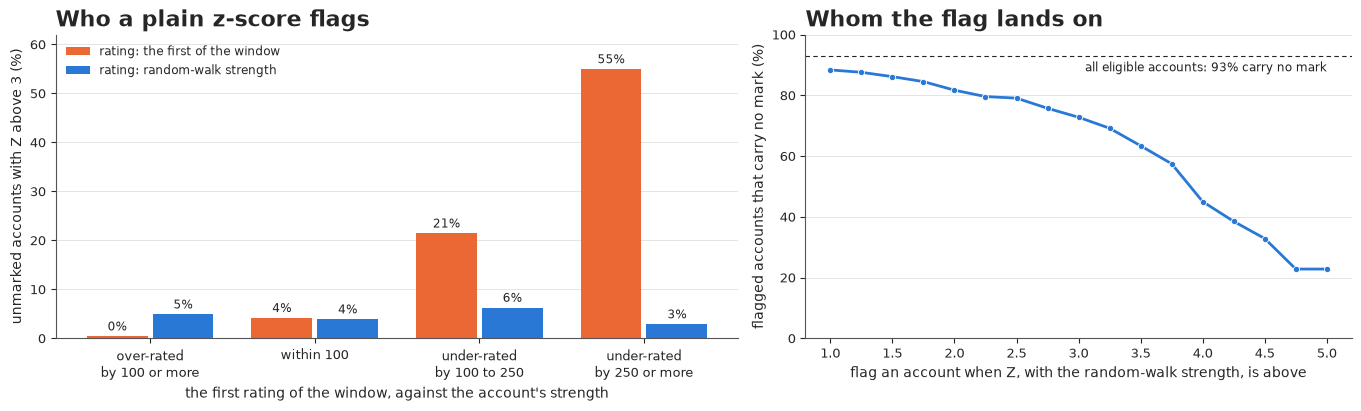

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.0), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
xs = np.arange(4)
ax.bar(xs - 0.2, stale["Z > 3, first rating"] * 100, width=0.37, color=ORANGE, label="rating: the first of the window")
ax.bar(xs + 0.2, stale["Z > 3, random-walk strength"] * 100, width=0.37, color=BLUE, label="rating: random-walk strength")
for x_, v1, v2 in zip(xs, stale["Z > 3, first rating"], stale["Z > 3, random-walk strength"]):
    ax.text(x_ - 0.2, v1 * 100 + 1.2, f"{v1:.0%}", ha="center", fontsize=8.5, color=INK)
    ax.text(x_ + 0.2, v2 * 100 + 1.2, f"{v2:.0%}", ha="center", fontsize=8.5, color=INK)
ax.set_xticks(xs, UNDER_LABELS)
ax.set_xlabel("the first rating of the window, against the account's strength")
ax.set_ylabel("unmarked accounts with Z above 3 (%)")
ax.set_ylim(0, 62)
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax.set_title("Who a plain z-score flags", loc="left")
tidy(ax)

ax = axes[1]
cuts = np.arange(1.0, 5.01, 0.25)
share_un = [weighted_share_unmarked(fit_ac["Z"] > c, fit_ac) for c in cuts]
ax.plot(cuts, np.array(share_un) * 100, "o-", color=BLUE, lw=2, ms=4.5, mec="white", mew=0.6)
ax.axhline(100 * (1 - BASE_RATE), color=INK, lw=0.8, ls=(0, (4, 3)))
ax.text(5.0, 100 * (1 - BASE_RATE) - 5, "all eligible accounts: 93% carry no mark", ha="right", fontsize=8.5, color=INK)
ax.set_ylim(0, 100)
ax.set_xlabel("flag an account when Z, with the random-walk strength, is above")
ax.set_ylabel("flagged accounts that carry no mark (%)")
ax.set_title("Whom the flag lands on", loc="left")
tidy(ax);

### Failure: three things are wrong with the plain z-score

**It is too wide.** Of the unmarked fitting accounts, 3.6% have $Z$ above 3, where the claim is 0.13%.
Part 4 explained a part of this. The rest is new: accounts differ from one another for good. The mean
surprise of unmarked accounts has a standard deviation of 0.28, where the number of games alone would
give 0.20. Some players are cleaner than their strength predicts, in every game, and a z-score has no
room for style.

**With a stale rating it flags the wrong people, which was the first warning.** The left panel groups
the unmarked accounts by how far the first rating of the window was from the strength they showed.
With the random-walk strength, the share above 3 is between 3% and 6% in every group. With the first
rating it is 4% for accounts rated about right, 21% for accounts under-rated by 100 to 250 points, and
55% for accounts under-rated by more. The warning said that a simple z-score flags every
fast-improving junior. The data say: more than half of them, not all, and "junior" needs translating.
The file has no ages. Nine in ten of the heavily under-rated accounts are newcomers on the default
1500, whose rating had not caught up with them. The mechanism is the one we were warned about.

**Its flags land mostly on accounts without a mark, which was the second warning.** This holds with
the right rating. Above 2, 82% of flagged accounts carry no mark; above 3, 73%; only beyond 4 does the
balance tip (right panel). Marked accounts are three to fifteen times as likely to be flagged as
unmarked ones, depending on the line, and they are outnumbered thirteen to one.

### A model for the two kinds of account

What we want is the probability that an account is marked given its score. Bayes' rule needs the
distribution of scores among unmarked accounts, the distribution among marked ones, and the base rate.
The histograms of the next figure suggest the form. Unmarked accounts make one bell. Marked accounts
look like the same bell with a second group to its right: some marked accounts play like everybody
else (a mark can be for boosting, or for games outside our window), and some do not. So the model has

- an **ordinary group**, in which an account with $n$ games has a score from
  $\mathcal{N}(m, \sqrt{\sigma_{\text{style}}^2 + 1/n})$: a lasting difference between accounts, plus
  the noise of a mean of $n$ surprises;
- a **high group**, shifted up by $\delta$, with a spread of its own;
- a share $\rho$ of the marked accounts in the high group, and a share $\epsilon$ of the unmarked ones.

The base rate is not estimated from the sample, where it is 21% by construction. It comes from the
counts behind the weights, 541 of 7,640.

The share $\epsilon$ was not in our first version. Without it the model holds that no unmarked account
can belong to the high group, and so that a high enough score proves a mark. We fit both versions, to
show what that assumption does.

In [17]:
def fit_mixture(frame, free_null=True, free_eps=True, report=True):
    """Account scores as a mixture: an ordinary group, and a high group that holds a share of the marked.
    free_null=False fixes the ordinary group at what independent moves imply; free_eps=False keeps every
    unmarked account out of the high group."""
    u_, m_ = frame[frame["marked"] == 0], frame[frame["marked"] == 1]
    with pm.Model():
        centre = pm.Normal("centre", 0.0, 0.3) if free_null else 0.0
        style = pm.HalfNormal("style", 0.3) if free_null else 0.0      # lasting differences between ordinary accounts
        shift = pm.HalfNormal("shift", 1.0)                            # how far above them the high group sits
        spread = pm.HalfNormal("spread", 0.5)
        rho = pm.Beta("rho", 1.0, 1.0)                                 # share of marked accounts in the high group
        eps = pm.Beta("eps", 1.0, 50.0) if free_eps else 0.0           # share of unmarked accounts in it
        pm.Beta("base", 1.0 + N_MARKED, 1.0 + N_UNMARKED)              # marked among eligible accounts: counted
        for name, d, share, mixed in (("unmarked", u_, eps, free_eps), ("marked", m_, rho, True)):
            noise = 1.0 / d["n"].to_numpy()
            low = pm.logp(pm.Normal.dist(centre, pt.sqrt(style ** 2 + noise)), d["score"].to_numpy())
            high = pm.logp(pm.Normal.dist(centre + shift, pt.sqrt(spread ** 2 + noise)), d["score"].to_numpy())
            pm.Potential(name, pt.logaddexp(pt.log1p(-share) + low, pt.log(share) + high).sum() if mixed else low.sum())
        idata = pm.sample(random_seed=RANDOM_SEED, target_accept=0.9, progressbar=False)
    if report:
        print("mixture:", diagnostics(idata))
        print(az.summary(idata, round_to=3)[["mean", "sd", "eti89_lb", "eti89_ub", "ess_bulk", "r_hat"]].to_string())
    draws = az.extract(idata, num_samples=400, random_seed=RANDOM_SEED)
    mix = {v: draws[v].to_numpy() for v in draws.data_vars}
    for name in ("centre", "style", "eps"):
        mix.setdefault(name, np.zeros(len(mix["rho"])))
    mix["diagnostics"] = diagnostics(idata)
    return mix


def densities(score, n, mix):
    """Density of an account score in the ordinary and in the high group, one column per posterior draw."""
    score, noise = np.asarray(score, float)[:, None], 1.0 / np.asarray(n, float)[:, None]
    low = stats.norm.pdf(score, mix["centre"], np.sqrt(mix["style"] ** 2 + noise))
    high = stats.norm.pdf(score, mix["centre"] + mix["shift"], np.sqrt(mix["spread"] ** 2 + noise))
    return low, high


def prob_marked(score, n, mix, base=None):
    """P(account is marked | its score), one column per posterior draw."""
    low, high = densities(score, n, mix)
    f_marked = (1 - mix["rho"]) * low + mix["rho"] * high
    f_unmarked = (1 - mix["eps"]) * low + mix["eps"] * high
    base = mix["base"] if base is None else base
    return base * f_marked / (base * f_marked + (1 - base) * f_unmarked)


REVIEW, ACCUSE = 0.5, 10 / 11          # the two decision lines of part 6: a human review, and an accusation
t0 = time.time()
MIX_SURE = fit_mixture(fit_ac, free_eps=False, report=False)          # first version: no unmarked account in the high group
MIX = fit_mixture(fit_ac)
print(f"({time.time() - t0:.0f} s; the version without eps: {MIX_SURE['diagnostics']})")
ac["q"] = prob_marked(ac["score"], ac["n"], MIX).mean(1)
ac["q_sure"] = prob_marked(ac["score"], ac["n"], MIX_SURE).mean(1)
fit_ac = ac[ac["train"]]
SAMPLE_SHARE = fit_ac["marked"].mean()
grid_score = np.linspace(-1.0, 2.2, 321)
q_grid = prob_marked(grid_score, np.full(len(grid_score), 24), MIX)
q_sure = prob_marked(grid_score, np.full(len(grid_score), 24), MIX_SURE).mean(1)
q_sample = prob_marked(grid_score, np.full(len(grid_score), 24), MIX, base=SAMPLE_SHARE).mean(1)
q_naive = 1 - stats.norm.sf(grid_score * np.sqrt(24))             # "one minus the p-value"
ceiling = MIX["base"] * MIX["rho"] / (MIX["base"] * MIX["rho"] + (1 - MIX["base"]) * MIX["eps"])
print("\nP(marked) for an account with 24 games, by mean surprise (posterior mean, 5% to 95%):")
for sc in (0.0, 0.4, 0.6, 0.8, 1.0, 1.5):
    i = np.abs(grid_score - sc).argmin()
    lo, hi = np.quantile(q_grid[i], [0.05, 0.95])
    print(f"  score {sc:.1f}: {q_grid[i].mean():.2f} ({lo:.2f} to {hi:.2f}) | no unmarked account in the high group: {q_sure[i]:.2f} "
          f"| base rate from the sample: {q_sample[i]:.2f} | one minus the p-value: {q_naive[i]:.4f}")
print(f"ceiling on P(marked), however high the score: {ceiling.mean():.2f} ({np.quantile(ceiling, 0.05):.2f} to "
      f"{np.quantile(ceiling, 0.95):.2f}); fitting accounts above 0.9 without eps: {int((fit_ac['q_sure'] > 0.9).sum())}, "
      f"with it: {int((fit_ac['q'] > 0.9).sum())}")
cal_bins = [0, 0.1, 0.2, 0.4, 0.6, 1.0]


def calibration(frame):
    return frame.groupby(pd.cut(frame["q"], cal_bins), observed=True).apply(
        lambda d: pd.Series({"accounts": len(d), "predicted": np.average(d["q"], weights=d["weight"]),
                             "marked (weighted share)": np.average(d["marked"], weights=d["weight"])}), include_groups=False)


print("\nfitting accounts, by predicted probability:")
print(calibration(fit_ac).round(3).to_string())

mixture: divergences 0, max r_hat 1.002, min ESS 976
         mean     sd  eti89_lb  eti89_ub  ess_bulk  r_hat
centre -0.043  0.008    -0.055    -0.030  4760.483  1.000
style   0.207  0.008     0.194     0.219  4428.008  1.000
shift   0.444  0.111     0.284     0.637   976.004  1.001
spread  0.414  0.050     0.329     0.490  1765.610  1.000
rho     0.384  0.094     0.246     0.543  1045.031  1.002
eps     0.005  0.005     0.000     0.014  2359.268  1.001
base    0.071  0.003     0.067     0.076  5456.355  1.000
(4 s; the version without eps: divergences 0, max r_hat 1.006, min ESS 996)

P(marked) for an account with 24 games, by mean surprise (posterior mean, 5% to 95%):
  score 0.0: 0.06 (0.05 to 0.06) | no unmarked account in the high group: 0.06 | base rate from the sample: 0.18 | one minus the p-value: 0.5000
  score 0.4: 0.09 (0.08 to 0.11) | no unmarked account in the high group: 0.09 | base rate from the sample: 0.27 | one minus the p-value: 0.9750
  score 0.6: 0.19 (0.15 to 0.2

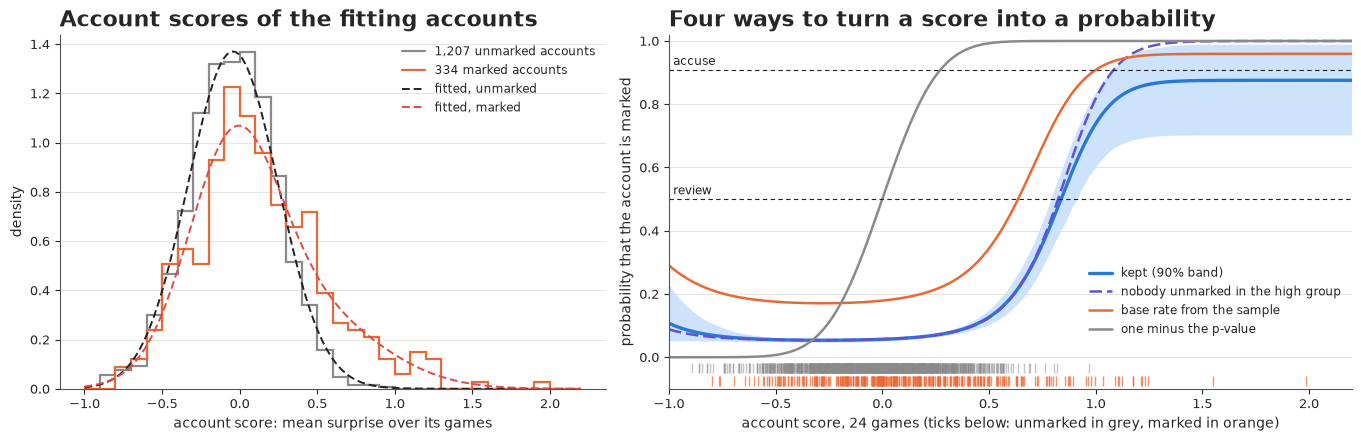

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
edges = np.arange(-1.0, 2.21, 0.1)
for frame, colour, label in ((un, MUTED, f"{len(un):,} unmarked accounts"), (ma, ORANGE, f"{len(ma)} marked accounts")):
    ax.stairs(np.histogram(frame["score"], edges, density=True)[0], edges, color=colour, lw=1.6, label=label)
low, high = densities(grid_score, np.full(len(grid_score), 24), MIX)
ax.plot(grid_score, ((1 - MIX["eps"]) * low + MIX["eps"] * high).mean(1), color=INK, lw=1.4, ls=(0, (4, 2)), label="fitted, unmarked")
ax.plot(grid_score, ((1 - MIX["rho"]) * low + MIX["rho"] * high).mean(1), color=RED, lw=1.4, ls=(0, (4, 2)), label="fitted, marked")
ax.set_xlabel("account score: mean surprise over its games")
ax.set_ylabel("density")
ax.legend(frameon=False, fontsize=8.5)
ax.set_title("Account scores of the fitting accounts", loc="left")
tidy(ax)

ax = axes[1]
ax.fill_between(grid_score, *np.quantile(q_grid, [0.05, 0.95], axis=1), color="#cde2fb", lw=0)
ax.plot(grid_score, q_grid.mean(1), color=BLUE, lw=2.4, label="kept (90% band)")
ax.plot(grid_score, q_sure, color=VIOLET, lw=1.8, ls=(0, (5, 2)), label="nobody unmarked in the high group")
ax.plot(grid_score, q_sample, color=ORANGE, lw=1.8, label="base rate from the sample")
ax.plot(grid_score, q_naive, color=MUTED, lw=1.8, label="one minus the p-value")
for y_, text in ((REVIEW, "review"), (ACCUSE, "accuse")):
    ax.axhline(y_, color=INK, lw=0.8, ls=(0, (4, 3)))
    ax.text(-0.98, y_ + 0.015, text, fontsize=8.5, color=INK)
ax.plot(fit_ac.loc[fit_ac["marked"] == 0, "score"], np.full(len(un), -0.035), "|", ms=7, color=MUTED, alpha=0.5)
ax.plot(fit_ac.loc[fit_ac["marked"] == 1, "score"], np.full(len(ma), -0.075), "|", ms=7, color=ORANGE, alpha=0.7)
ax.set_xlim(-1.0, 2.2)
ax.set_ylim(-0.1, 1.02)
ax.set_xlabel("account score, 24 games (ticks below: unmarked in grey, marked in orange)")
ax.set_ylabel("probability that the account is marked")
ax.legend(frameon=False, fontsize=8.3, loc="lower right", bbox_to_anchor=(1.0, 0.12))
ax.set_title("Four ways to turn a score into a probability", loc="left")
tidy(ax);

The mixture samples cleanly. About 38% of the marked accounts belong to the high group (anywhere from
a quarter to a half), which sits 0.44 above the ordinary group and is twice as wide. The share of
unmarked accounts in the high group is about half a percent, with zero and 1.4% both plausible.

The right panel puts four readings of the same score side by side, for an account with 24 games.

*One minus the p-value* (grey) answers "how unlikely is this score for an honest account" and is read
as "how likely is this account to be dishonest". It passes 97% at a score of 0.4, where 9% of accounts
are marked.

*The sample's base rate* (orange) is the quiet version of the same mistake: the right model with the
share of marked accounts in the file, 21%, which is what a classifier trained on this file would use
unless told otherwise. It gives an average account 18%, where the population figure is 6%, and it
reaches one half at a score near 0.65, where the kept curve says about one in five.

*No unmarked account in the high group* (violet) agrees with the kept curve up to a score of about 0.8
and then climbs to certainty. Nine fitting accounts get a probability above 0.9 from it.

*The kept curve* (blue) levels off just under 0.9, with a 90% band from about 0.7 to 0.99. That
ceiling is $\pi\rho / (\pi\rho + (1 - \pi)\epsilon)$, with $\pi$ the base rate: however extreme the
score, the account is either a marked account of the high group or one of the unmarked ones there, and
half a percent of a large population is not few. The band is wide because only a handful of accounts
inform $\epsilon$. In the far tail the data can say "probably marked" and cannot say "certainly".

> **The choice.** The probability of a mark comes from a two-group mixture of account scores, with the
> base rate counted in the population (7.1%) and a small share of unmarked accounts allowed in the high
> group. *Rejected:* one minus the p-value (97% where the answer is 9%); the sample's share as base
> rate (three times too high, by our own sampling design); and certainty in the tail (it assumes that
> the platform has marked everyone who plays like that). *Considered:* a heavier-tailed ordinary group
> in place of $\epsilon$. *What would change our mind:* the prior on $\epsilon$, Beta(1, 50), does real
> work. A fair-play team that had reviewed by hand a sample of high-scoring unmarked accounts would
> replace it with a count.

## 6 · The threshold: whom to review, whom to accuse

A probability is not a decision. Acting on an account that is not marked has a cost, missing one that
is marked has another, and only their ratio matters. If a false accusation costs $k$ misses, acting on
an account with probability $q$ has an expected cost of $k(1 - q)$ and not acting has an expected cost
of $q$, so the rule is to act when $q \ge k/(k+1)$. Nothing in the data says what $k$ is. A fair-play
team has at least two actions: sending an account to a human reviewer, where a wasted review costs
about as much as a miss ($k = 1$, act above 0.5), and closing an account, where we take a false
accusation to be ten times as bad as a miss ($k = 10$, act above 10/11).

How well the rule will do is uncertain, because the mixture is. For each of 400 posterior draws we
imagine a population of accounts from that draw, apply the fixed rule at every threshold, and count
the false accusations and the marked accounts caught per 1,000 accounts.

In [19]:
N_GRID = np.unique(ac["n"])
Q_RULE = np.array([prob_marked(grid_score, np.full(len(grid_score), n_), MIX).mean(1) for n_ in N_GRID])   # the rule, fixed


def rule(score, n):
    """The posterior-mean probability of a mark, read off the fixed rule (interpolated in the score)."""
    out = np.empty(len(score))
    row = np.searchsorted(N_GRID, n)
    for r_ in np.unique(row):
        m_ = row == r_
        out[m_] = np.interp(score[m_], grid_score, Q_RULE[r_])
    return out


THRESHOLDS = np.linspace(0.02, 0.98, 49)
COST_RATIOS = [1, 3, 10]                                # a false accusation costs this many missed marked accounts
gen = np.random.default_rng(RANDOM_SEED + 6)
N_SIM = 20_000
fa, caught = np.empty((len(MIX["rho"]), len(THRESHOLDS))), np.empty((len(MIX["rho"]), len(THRESHOLDS)))
for d in range(len(MIX["rho"])):                        # one imagined population of accounts per posterior draw
    n_ = gen.choice(fit_ac["n"].to_numpy(), N_SIM)
    marked = gen.random(N_SIM) < MIX["base"][d]
    high = gen.random(N_SIM) < np.where(marked, MIX["rho"][d], MIX["eps"][d])
    score = np.where(high, gen.normal(MIX["centre"][d] + MIX["shift"][d], np.sqrt(MIX["spread"][d] ** 2 + 1 / n_)),
                     gen.normal(MIX["centre"][d], np.sqrt(MIX["style"][d] ** 2 + 1 / n_)))
    q_ = rule(score, n_)
    accused = q_[:, None] >= THRESHOLDS[None, :]
    fa[d] = 1000 * (accused & ~marked[:, None]).mean(0)
    caught[d] = 1000 * (accused & marked[:, None]).mean(0)


def realised(frame, thresholds=THRESHOLDS):
    """False accusations and marked accounts caught per 1,000 eligible accounts, for real accounts."""
    w = frame["weight"].to_numpy() / frame["weight"].sum() * 1000
    accused = frame["q"].to_numpy()[:, None] >= np.atleast_1d(thresholds)[None, :]
    is_marked = frame["marked"].to_numpy()[:, None] == 1
    return (w[:, None] * (accused & ~is_marked)).sum(0), (w[:, None] * (accused & is_marked)).sum(0)


print(f"per 1,000 eligible accounts, {1000 * MIX['base'].mean():.0f} are marked. Cost of a rule against accusing nobody, "
      "in missed marked accounts\n(posterior mean and 5% to 95%):")
for k in COST_RATIOS:
    net = k * fa - caught
    best = net.mean(0).argmin()
    lo, hi = np.quantile(net[:, best], [0.05, 0.95])
    print(f"  a false accusation costs {k:>2} misses: best threshold {THRESHOLDS[best]:.2f} (theory {k / (k + 1):.2f}), cost "
          f"{net[:, best].mean():+.1f} ({lo:+.1f} to {hi:+.1f}), with {fa[:, best].mean():.1f} false accusations and "
          f"{caught[:, best].mean():.1f} marked accounts caught; P(the rule beats doing nothing) = {(net[:, best] < 0).mean():.2f}")
print("\nfitting accounts by decision threshold:")
for thr in (REVIEW, 0.75, ACCUSE):
    f = fit_ac["q"] >= thr
    print(f"  P(marked) >= {thr:.2f}: {int(f.sum())} accounts, {int(fit_ac.loc[f, 'marked'].sum())} of them marked")

per 1,000 eligible accounts, 71 are marked. Cost of a rule against accusing nobody, in missed marked accounts
(posterior mean and 5% to 95%):
  a false accusation costs  1 misses: best threshold 0.50 (theory 0.50), cost -2.9 (-4.9 to -0.9), with 1.9 false accusations and 4.8 marked accounts caught; P(the rule beats doing nothing) = 0.99
  a false accusation costs  3 misses: best threshold 0.76 (theory 0.75), cost -1.0 (-3.0 to +1.4), with 0.5 false accusations and 2.6 marked accounts caught; P(the rule beats doing nothing) = 0.81
  a false accusation costs 10 misses: best threshold 0.88 (theory 0.91), cost +0.0 (+0.0 to +0.0), with 0.0 false accusations and 0.0 marked accounts caught; P(the rule beats doing nothing) = 0.00

fitting accounts by decision threshold:
  P(marked) >= 0.50: 22 accounts, 21 of them marked
  P(marked) >= 0.75: 12 accounts, 12 of them marked
  P(marked) >= 0.91: 0 accounts, 0 of them marked


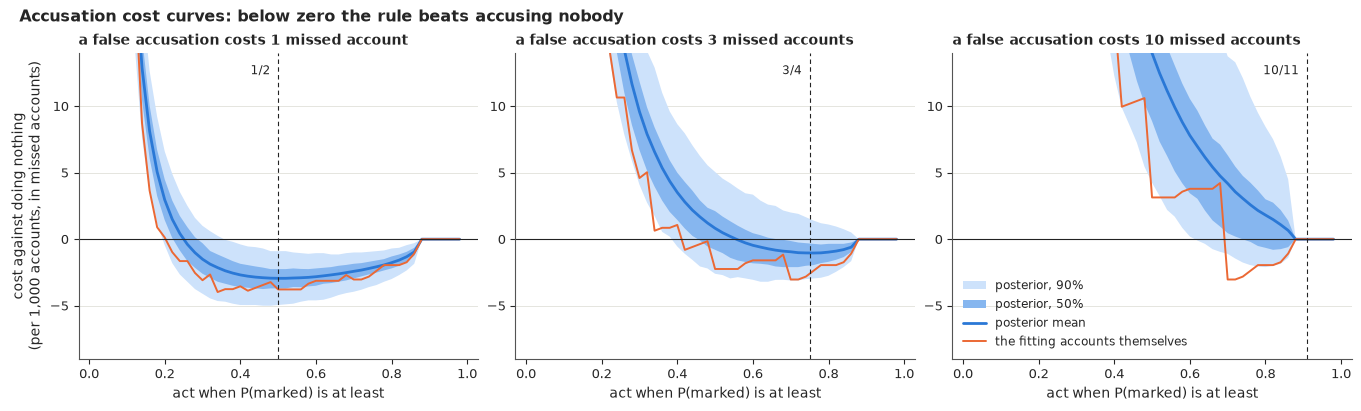

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0), sharex=True)
fa_fit, caught_fit = realised(fit_ac)
for ax, k in zip(axes, COST_RATIOS):
    net = k * fa - caught                                # cost against accusing nobody, per 1,000 eligible accounts
    ax.fill_between(THRESHOLDS, *np.quantile(net, [0.05, 0.95], axis=0), color="#cde2fb", lw=0, label="posterior, 90%")
    ax.fill_between(THRESHOLDS, *np.quantile(net, [0.25, 0.75], axis=0), color="#86b6ef", lw=0, label="posterior, 50%")
    ax.plot(THRESHOLDS, net.mean(0), color=BLUE, lw=2, label="posterior mean")
    ax.plot(THRESHOLDS, k * fa_fit - caught_fit, color=ORANGE, lw=1.4, label="the fitting accounts themselves")
    ax.axhline(0, color=INK, lw=0.8)
    ax.axvline(k / (k + 1), color=INK, lw=0.8, ls=(0, (4, 3)))
    ax.text(k / (k + 1) - 0.02, 0.96, f"{k}/{k + 1}", transform=ax.get_xaxis_transform(), ha="right", va="top", fontsize=8.5, color=INK)
    ax.set_ylim(-9, 14)
    ax.set_xlabel("act when P(marked) is at least")
    ax.set_title(f"a false accusation costs {k} missed account{'s' if k > 1 else ''}", loc="left", fontsize=10)
    tidy(ax)
axes[0].set_ylabel("cost against doing nothing\n(per 1,000 accounts, in missed accounts)")
axes[2].legend(frameon=False, fontsize=8.3, loc="lower left")
fig.suptitle("Accusation cost curves: below zero the rule beats accusing nobody", x=0.01, ha="left", fontsize=11.5);

Each panel is a cost ratio. The curve is the expected cost of the rule minus the cost of doing
nothing, per 1,000 eligible accounts and in units of one missed account: a rule is worth having where
its curve is below zero. The orange line is the same count on the fitting accounts themselves.

**A review queue pays.** At $k = 1$ the curve is lowest near one half, as the theory says, and the
saving is about 3 accounts per 1,000 (between 1 and 5): the rule sends six or seven accounts to
review, of which four or five are marked.

**An accusation at ten to one does not.** At $k = 10$ the curve never goes below zero. It reaches zero
where the rule stops acting on anybody, at the ceiling of part 5. The orange line does dip below zero
just before that, because the twelve fitting accounts with the highest probabilities all happen to be
marked; the band says not to count on it. At $k = 3$ the picture is in between: a saving of one
account per 1,000, with four chances in five that the rule beats doing nothing.

**The detector sees a small part of the problem.** There are 71 marked accounts per 1,000, and the
best review rule catches about five of them. About six in ten marked accounts are in the ordinary
group to begin with, and the high group overlaps it. Whatever the marks were given for, the larger
part of it is invisible in two dozen analysed games.

On the fitting accounts the two lines select 22 accounts for review, 21 of them marked, and nobody for
an accusation.

> **The choice.** Review above 0.5; accuse above 10/11, which on this evidence means nobody.
> *Rejected:* three sigma, a line drawn on the score and not on the probability, which carries no cost
> and no base rate (part 7 counts what it does). *Considered:* a single action at three to one, which
> would act on about three accounts per 1,000. *What would change our mind:* hand-reviewed cases,
> more than more games. A longer record would bring more accounts up to the ceiling but would not
> raise it, because the ceiling comes from $\epsilon$.

## 7 · The test: 1,000 accounts no model has seen

The 1,000 accounts set aside in part 1 played no part in the move model, the spread or the mixture.
(Their results did enter the strength smoother of part 2, which uses no labels and no evaluations.)
We run them through the chain as it stands.

In [21]:
test_ac = ac[~ac["train"]]
test_mv = mv[~mv["train"]]
gtest = gs[~gs["train"]]
p_ = np.clip(test_mv["p_pos"].to_numpy(), 1e-9, 1 - 1e-9)
p_fit = np.clip(fit_mv["p_pos"].to_numpy(), 1e-9, 1 - 1e-9)
print(f"move model, log score per move: fitting accounts {np.where(fit_mv['slip'], np.log(p_fit), np.log1p(-p_fit)).mean():.4f}, "
      f"test accounts {np.where(test_mv['slip'], np.log(p_), np.log1p(-p_)).mean():.4f}")
gu = gtest[acc["marked"].to_numpy()[gtest["a"]] == 0]
print(f"surprise of {len(gu):,} games of unmarked test accounts: mean {gu['s'].mean():.3f}, sd {gu['s'].std():.3f}, "
      f"{(gu['s'] > 2).mean():.4f} above 2 (normal: {stats.norm.sf(2):.4f})")
tu = test_ac[test_ac["marked"] == 0]
print(f"account scores of unmarked test accounts: mean {tu['score'].mean():.3f}, sd {tu['score'].std():.3f}; the mixture expects "
      f"{MIX['centre'].mean():.3f} and {np.sqrt(MIX['style'].mean() ** 2 + (1 / tu['n']).mean()):.3f}")
print("\ntest accounts, by predicted probability:")
print(calibration(test_ac).round(3).to_string())
print("\ntest accounts by decision threshold:")
test_rows = []
for thr in (REVIEW, 0.75, ACCUSE):
    f = test_ac["q"] >= thr
    fa_t, caught_t = realised(test_ac, thr)
    test_rows.append({"threshold": round(thr, 2), "accused": int(f.sum()), "marked": int(test_ac.loc[f, "marked"].sum()),
                      "unmarked": int((1 - test_ac.loc[f, "marked"]).sum()),
                      "predicted marked": test_ac.loc[f, "q"].sum(), "false per 1,000": fa_t[0],
                      "caught per 1,000": caught_t[0]})
print(pd.DataFrame(test_rows).round(2).to_string(index=False))
zt = test_ac["Z"]
print(f"\nthe plain z-score on the same accounts: Z > 3 flags {int((zt > 3).sum())}, of whom {int(test_ac.loc[zt > 3, 'marked'].sum())} "
      f"marked; share with no mark, weighted: {weighted_share_unmarked(zt > 3, test_ac):.2f}")

move model, log score per move: fitting accounts -0.5825, test accounts -0.5838
surprise of 21,950 games of unmarked test accounts: mean -0.060, sd 0.976, 0.0133 above 2 (normal: 0.0228)
account scores of unmarked test accounts: mean -0.055, sd 0.305; the mixture expects -0.043 and 0.285

test accounts, by predicted probability:
            accounts  predicted  marked (weighted share)
q                                                       
(0.0, 0.1]     898.0      0.059                    0.058
(0.1, 0.2]      68.0      0.138                    0.182
(0.2, 0.4]      23.0      0.266                    0.153
(0.4, 0.6]       6.0      0.466                    0.360
(0.6, 1.0]       5.0      0.740                    0.530

test accounts by decision threshold:
 threshold  accused  marked  unmarked  predicted marked  false per 1,000  caught per 1,000
      0.50        7       6         1              4.88             1.17              1.99
      0.75        3       3         0             

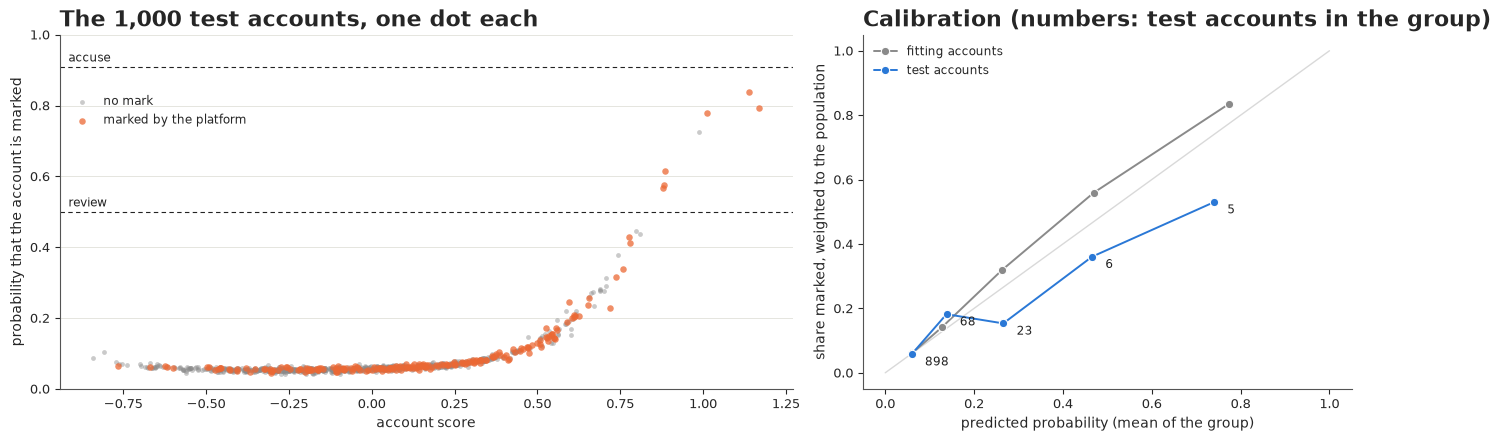

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
jit = np.random.default_rng(3).normal(0, 0.004, len(test_ac))
for flag, colour, label, size in ((0, MUTED, "no mark", 12), (1, ORANGE, "marked by the platform", 22)):
    d = test_ac[test_ac["marked"] == flag]
    ax.scatter(d["score"], d["q"] + jit[test_ac["marked"].to_numpy() == flag], s=size, color=colour, alpha=0.75 if flag else 0.45,
               lw=0, label=label)
for y_, text in ((REVIEW, "review"), (ACCUSE, "accuse")):
    ax.axhline(y_, color=INK, lw=0.8, ls=(0, (4, 3)))
    ax.text(0.012, y_ + 0.015, text, fontsize=8.5, color=INK, transform=ax.get_yaxis_transform())
ax.set_xlabel("account score")
ax.set_ylabel("probability that the account is marked")
ax.set_ylim(0, 1)
ax.legend(frameon=False, fontsize=8.5, loc="upper left", bbox_to_anchor=(0.0, 0.86))
ax.set_title("The 1,000 test accounts, one dot each", loc="left")
tidy(ax)

ax = axes[1]
ax.plot([0, 1], [0, 1], color=LIGHT, lw=1)
for frame, colour, label in ((fit_ac, MUTED, "fitting accounts"), (test_ac, BLUE, "test accounts")):
    c = calibration(frame)
    ax.plot(c["predicted"], c["marked (weighted share)"], "o-", ms=6, color=colour, mec="white", mew=0.8, lw=1.4, label=label)
    if frame is test_ac:
        for x_, y_, n_ in zip(c["predicted"], c["marked (weighted share)"], c["accounts"]):
            ax.text(x_ + 0.03, y_ - 0.035, f"{n_:.0f}", fontsize=8.5, color=INK)
ax.set_xlabel("predicted probability (mean of the group)")
ax.set_ylabel("share marked, weighted to the population")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax.set_title("Calibration (numbers: test accounts in the group)", loc="left")
tidy(ax, grid=None);

The links hold one by one. The move model scores -0.5838 per move on the test accounts against -0.5825
on the fitting accounts. The surprise of their games has a standard deviation of 0.98, where the
fitted spread promised 1. The scores of the unmarked test accounts have a mean of about -0.05 and a
standard deviation of about 0.30, close to the -0.04 and 0.29 that the mixture expected.

Then the labels. The left panel shows every test account. Seven lie above the review line and six of
them are marked, where the probabilities themselves predicted about five. Three are above 0.75 and all
three are marked. None reaches the accusation line. Per 1,000 eligible accounts the review queue holds
about one account without a mark and two with one, out of 69.

The calibration panel is the stricter test, and it is less flattering. In the lowest band, where nine
accounts in ten are, predicted and observed shares agree: 5.9% against 5.8%. In the upper bands the
test accounts sit below the diagonal. Of the five accounts with a predicted probability of 0.74 on
average, four are marked; once the unmarked one is counted for the 3.5 accounts it stands for, that is
53% of the population they represent. Five accounts cannot tell a calibration error from luck, and
the fitting accounts erred on the other side.

Compare the plain z-score on the same accounts. A line at $Z > 3$ flags 77 of them, 35 marked and 42
not, and weighted to the population 81% of its flags fall on accounts without a mark. The second
warning describes that rule exactly. It does not describe the review queue, six of whose seven
accounts are marked. The two use nearly the same score. What separates them is where the line is
drawn, and on which scale.

## 8 · Which of our choices mattered?

Five choices in this notebook had a rival that a competent analyst in a hurry might have taken: the
first rating of the window in place of the walk; no position in the move model; independent moves and
identical accounts; the sample's share of marked accounts as the base rate; and no unmarked account
in the high group. Taking or leaving each gives $2^5 = 32$ analysts. Each builds their own scores,
fits the mixture of part 5 in PyMC under their own assumptions, and applies the two decision lines to
the 1,000 test accounts. The figure below is a specification curve (Simonsohn, Simmons and Nelson
2020): every analyst, ordered by the unmarked accounts they send to review, with their choices
underneath.

In [23]:
def fit_spread(g):
    """The spread model of part 4 by maximum likelihood, on the fitting accounts' games."""
    d = g[g["train"]]
    z, v = d["z"].to_numpy(), (d["v"].to_numpy() - V_MID) / V_MID
    nll = lambda th: (th[1] + th[2] * v + 0.5 * ((z - th[0]) / np.exp(th[1] + th[2] * v)) ** 2).sum()
    return tuple(optimize.minimize(nll, [0.0, 0.2, 0.0], method="BFGS").x)


mv["p_plain_first"], mv["p_pos_first"] = slip_prob(mv, "first", M_PLAIN), slip_prob(mv, "first", M_POS)
FORKS = {  # choice: (what we did, what we rejected)
    "rating": ("random-walk strength", "first rating of the window"),
    "position": ("in the model", "ignored"),
    "spread": ("fitted spread and style", "independent moves"),
    "base rate": ("counted in the population", "the sample's share"),
    "unmarked": ("some play like the marked", "none does"),
}
is_test, is_marked = ~acc["train"].to_numpy(), acc["marked"].to_numpy() == 1
per_1000 = acc["weight"].to_numpy() / acc.loc[is_test, "weight"].sum() * 1000
t0 = time.time()
worlds, worst = [], ""
for r_ in range(2):
    for p_ in range(2):
        g = game_scores(mv, mv[("p_pos", "p_plain")[p_] + ("", "_first")[r_]].to_numpy())
        for s_ in range(2):
            g["s"] = surprise(g, fit_spread(g)) if s_ == 0 else g["z"]
            sc = account_scores(g)
            for e_ in range(2):
                mix = fit_mixture(sc[sc["train"]], free_null=s_ == 0, free_eps=e_ == 0, report=False)
                worst = max(worst, mix["diagnostics"], key=lambda t: float(t.split("max r_hat ")[1].split(",")[0]) if t else 0)
                for b_ in range(2):
                    q = prob_marked(sc["score"], sc["n"], mix, base=None if b_ == 0 else SAMPLE_SHARE).mean(1)
                    row = {"rating": r_, "position": p_, "spread": s_, "base rate": b_, "unmarked": e_}
                    for name, thr in (("review", REVIEW), ("accuse", ACCUSE)):
                        f = (q >= thr) & is_test
                        row[f"{name}: no mark"], row[f"{name}: marked"] = int((f & ~is_marked).sum()), int((f & is_marked).sum())
                        row[f"{name}: false per 1,000"] = per_1000[f & ~is_marked].sum()
                        row[f"{name}: caught per 1,000"] = per_1000[f & is_marked].sum()
                    f = (q >= REVIEW) & is_test & ~is_marked
                    row["under-rated among the false"] = float(np.mean(under[f] > 100)) if f.any() else np.nan
                    worlds.append(row)
worlds = pd.DataFrame(worlds)
worlds["rejected"] = worlds[list(FORKS)].sum(axis=1)
print(f"{len(worlds)} analysts in {time.time() - t0:.0f} s; worst of the 16 mixture fits: {worst}")
print(f"marked accounts per 1,000 eligible in the test set: {per_1000[is_test & is_marked].sum():.0f}; under-rated by more than "
      f"100 among unmarked test accounts: {np.mean(under[is_test & ~is_marked] > 100):.2f}")
ours = worlds[worlds["rejected"] == 0].iloc[0]
print("our choices again (spread by maximum likelihood on all games): review "
      f"{ours['review: marked'] + ours['review: no mark']:.0f} test accounts, {ours['review: marked']:.0f} of them marked; "
      f"accuse {ours['accuse: marked'] + ours['accuse: no mark']:.0f}")
effects = []
for fork in FORKS:
    one = worlds[(worlds["rejected"] == 1) & (worlds[fork] == 1)].iloc[0]
    main = worlds.groupby(fork)[["review: false per 1,000", "review: caught per 1,000", "accuse: false per 1,000"]].mean()
    effects.append({"choice": fork, "rejected option": FORKS[fork][1],
                    "review, alone: no mark": one["review: no mark"], "marked": one["review: marked"],
                    "accuse, alone: no mark": one["accuse: no mark"], "marked ": one["accuse: marked"],
                    "review false per 1,000, mean shift": main.loc[1].iloc[0] - main.loc[0].iloc[0],
                    "review caught per 1,000, mean shift": main.loc[1].iloc[1] - main.loc[0].iloc[1],
                    "accuse false per 1,000, mean shift": main.loc[1].iloc[2] - main.loc[0].iloc[2]})
print(pd.DataFrame(effects).round(1).to_string(index=False))
show = ["rating", "position", "spread", "base rate", "unmarked", "review: no mark", "review: marked", "accuse: no mark",
        "accuse: marked", "under-rated among the false"]
print(worlds.sort_values(["review: false per 1,000", "review: caught per 1,000"])[show].round(2).to_string(index=False))

32 analysts in 39 s; worst of the 16 mixture fits: divergences 0, max r_hat 1.007, min ESS 957
marked accounts per 1,000 eligible in the test set: 69; under-rated by more than 100 among unmarked test accounts: 0.32
our choices again (spread by maximum likelihood on all games): review 7 test accounts, 6 of them marked; accuse 0
   choice            rejected option  review, alone: no mark  marked  accuse, alone: no mark  marked   review false per 1,000, mean shift  review caught per 1,000, mean shift  accuse false per 1,000, mean shift
   rating first rating of the window                     1.0     4.0                     0.0      0.0                                14.8                                  2.2                                15.4
 position                    ignored                     1.0     4.0                     0.0      0.0                                 8.0                                  0.8                                 5.6
   spread          independent moves  

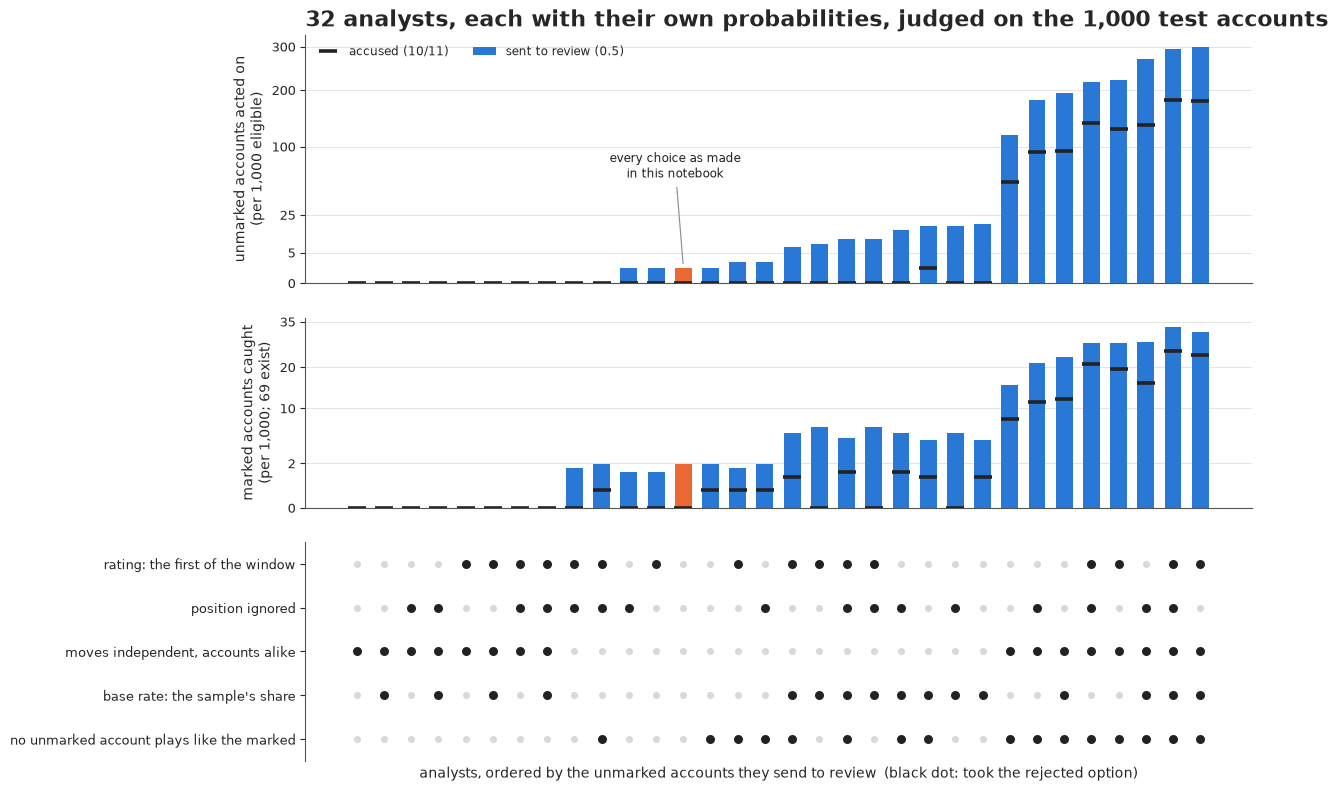

In [24]:
ws = worlds.sort_values(["review: false per 1,000", "review: caught per 1,000"]).reset_index(drop=True)
xw = np.arange(len(ws))
is_ours = (ws["rejected"] == 0).to_numpy()
root = (np.sqrt, np.square)
fig, axes = plt.subplots(3, 1, figsize=(12.5, 7.8), sharex=True, gridspec_kw={"height_ratios": [1.7, 1.3, 1.5], "hspace": 0.1})
for ax, what, ylabel, ticks in ((axes[0], "false", "unmarked accounts acted on\n(per 1,000 eligible)", [0, 5, 25, 100, 200, 300]),
                                (axes[1], "caught", "marked accounts caught\n(per 1,000; 69 exist)", [0, 2, 10, 20, 35])):
    ax.bar(xw, ws[f"review: {what} per 1,000"], width=0.62, color=np.where(is_ours, ORANGE, BLUE), label="sent to review (0.5)")
    ax.plot(xw, ws[f"accuse: {what} per 1,000"], "_", ms=13, mew=2.6, color=INK, label="accused (10/11)")
    ax.set_yscale("function", functions=root)
    ax.set_yticks(ticks)
    ax.set_ylabel(ylabel)
    tidy(ax)
axes[0].legend(frameon=False, fontsize=8.5, loc="upper left", ncol=2)
axes[0].annotate("every choice as made\nin this notebook", (xw[is_ours][0], 1.5), (xw[is_ours][0] - 0.3, 60), fontsize=8.8, color=INK,
                 ha="center", arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 0.8})
axes[0].set_title("32 analysts, each with their own probabilities, judged on the 1,000 test accounts", loc="left")
ax = axes[2]
labels = {"rating": "rating: the first of the window", "position": "position ignored", "spread": "moves independent, accounts alike",
          "base rate": "base rate: the sample's share", "unmarked": "no unmarked account plays like the marked"}
for r_, fork in enumerate(FORKS):
    on = ws[fork].to_numpy() == 1
    ax.scatter(xw[~on], np.full((~on).sum(), r_), s=26, color=LIGHT, lw=0)
    ax.scatter(xw[on], np.full(on.sum(), r_), s=42, color=INK, lw=0)
ax.set_yticks(range(len(FORKS)), [labels[f] for f in FORKS])
ax.set_ylim(len(FORKS) - 0.5, -0.5)
ax.set_xticks([])
ax.set_xlabel("analysts, ordered by the unmarked accounts they send to review  (black dot: took the rejected option)")
ax.grid(False)
ax.spines[["top", "right", "bottom"]].set_visible(False);

Read the figure from the bottom. Each column is an analyst, the black dots are the rejected options
that analyst took, the bars are the accounts sent to review per 1,000 (unmarked above, marked below),
and the black ticks are the accounts the analyst would accuse. The orange column is this notebook:
seven test accounts for review, six of them marked, and nobody accused.

**Two choices are dangerous together and harmless apart.** The eight analysts on the right assume both
that moves are independent with accounts alike, and that no unmarked account plays like the marked
ones. They send between 100 and 256 unmarked test accounts to review, of 793, and would accuse
between 47 and 151 of them. The eight on the far left make the first assumption without the second,
and act on nobody at all: their ordinary group is too narrow, so their $\epsilon$ swells to absorb
every honest account that does not fit, and the ceiling of part 5 falls below one half. One wrong
assumption made the model blind. The second, added to it, made it reckless.

**The base rate is the choice that costs innocent accounts all by itself.** Taking the sample's share
turns a review queue of one unmarked and six marked test accounts into one of sixteen and fourteen.
The same analyst accuses three accounts, and all three are marked: an overconfident model can be
lucky.

**The stale rating and the missing position cost power, not fairness, once the spread is fitted.**
Each of them alone reviews five accounts where we review seven, four of them marked: a wrong
expectation makes honest accounts look more varied, and the fitted spread widens to cover them. The
stale rating still decides *who* is flagged falsely. Among the analysts who use the sample's base
rate, 83% to 89% of the unmarked accounts sent to review were under-rated by 100 points or more when
the first rating is used, and 19% to 31% when the walk is (32% of unmarked test accounts are).

**Our caution cost something, in this test.** The analyst who differs from us only in holding that no
unmarked account plays like the marked ones reviews the same seven accounts and accuses one, and that
one is marked. The bolder model made no mistake that ours avoided. We keep $\epsilon$ because the
mistake it guards against is the expensive one; the test could not tell the two apart.

## Summary

- **"Did they cheat?" is a chain of five models, and its answer is a probability with a ceiling.** No
  score lifts the probability of a mark above about 0.9 (0.7 to 0.99), so at ten to one nobody is
  accused. A review queue above 0.5 held seven of the 1,000 test accounts, six of them marked.
  *Limit:* the yardstick is the platform's mark as of 2026, which covers boosting as well as engine
  use and misses whoever was never caught.
- **Strength: the platform's rating wins on results, ours on moves.** One rating per account predicts
  held-out games no better than a coin, because 46% of accounts start on the default 1500. The
  published rating beats our walk at predicting results (-0.615 against -0.617) and loses to it at
  predicting slips. *Limit:* fortnightly steps make the walk slow for an account that keeps moving.
- **Move quality: the position matters more than the player.** Slip rates run from 0 to 57% across
  situations, and from 50% to under 30% across the range of strength. A model without the position
  passes its own check and scores games by how early they are decided. *Limit:* difficulty is built
  from one evaluation per move, and one-sided games still score a little too well.
- **Surprise: the spread has to be measured.** Game z-scores are 1.24 times too wide, and the textbook
  repair, a game effect, has the right size and the wrong shape.
- **Both warnings held for the z-score.** With a stale rating, 55% of the unmarked accounts
  under-rated by 250 points or more have $Z > 3$, against 3% with the walk; nine in ten of them are
  newcomers on the default rating, not prodigies. And 81% of the test accounts flagged by $Z > 3$,
  weighted, carry no mark. The base rate enters twice: marked accounts are 7% of the population, and
  21% of our own file by design.
- **Of 32 analysts, the dangerous ones combined two assumptions.** Independent moves, plus the belief
  that everyone who plays like the marked accounts is marked: 100 to 256 unmarked test accounts sent
  to review. Neither did that alone. *Limit:* one test set; counts of five and seven do not rank
  models.

## Try it yourself

1. **Count only mistakes.** Set `SLIP = 10.0` and rerun. How much smaller is the share of marked
   accounts in the high group, and how many test accounts reach the review line?
2. **Hand the rating link to the platform.** After part 2, replace `mv["strength"]` by
   `mv["published"]` and rerun parts 3 to 7. Does the review queue change?
3. **How many games does a decision need?** The number of games `n` enters the mixture only through
   the noise term `1 / n`. With `prob_marked` and the fitted `MIX`, draw the probability curve for an
   account with 100 games. Which part of the curve moves, why does the ceiling stay where it is, and
   what would have to be measured to move it?

In [25]:
print(f"total run time: {time.time() - T_START:.0f} s")

total run time: 120 s
